# Segunda Entrega — Transferencia de una Sparse Attention-based Transformer Network para el pronóstico de PM2.5

Universidad Externado de Colombia, Facultad de Ciencia de Datos. Proyecto Integrador de Deep Learning.
Estudiante: Johan Velandia. Profesor: Wilmer Darío Pineda Ríos. Segunda Entrega, 2026.

Este notebook documenta la Segunda Entrega del proyecto: replicar el método propuesto por Zhang y Zhang (2023) sobre los datos originales de Beijing, trasladarlo a un problema local —el pronóstico de PM2.5 en la estación Fontibón, Bogotá— y evaluar distintas configuraciones de entrenamiento, incluyendo transferencia de aprendizaje, entre ambos dominios. Las celdas de código se limitan a cargar y mostrar resultados ya calculados; la única excepción es una prueba rápida de la arquitectura sobre datos sintéticos, que no constituye un entrenamiento real.

**Declaración de uso de IA**: el desarrollo de este proyecto contó con la asistencia de un modelo de lenguaje (Claude, Anthropic) como herramienta de programación en pareja. Las decisiones de diseño, los resultados y las interpretaciones presentadas aquí fueron revisados y validados por el autor antes de incluirse.

## 0. Configuración y reproducibilidad

El proyecto usa tres semillas aleatorias (42, 123 y 2026) para evaluar la estabilidad de los resultados. El conjunto de prueba de Fontibón no se utiliza en ninguna celda de este notebook: solo se consulta la partición de validación para comparar configuraciones. El conjunto de prueba de Beijing (año 2014) sí se usa, pero una única vez, al cerrar la réplica del artículo en la sección 4.

In [1]:
import sys
from pathlib import Path

def _find_project_root(start: Path) -> Path:
    # Same marker-file approach as src/utils/paths.py (requirements.txt),
    # so this works whether the notebook runs from notebooks/ or the root,
    # regardless of whether a "notebooks" subfolder happens to exist.
    for parent in [start, *start.parents]:
        if (parent / "requirements.txt").exists():
            return parent
    return start

PROJECT_ROOT_FROM_NOTEBOOK = _find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT_FROM_NOTEBOOK))

from IPython.display import Image, display
import numpy as np
import tensorflow as tf

from src.utils.paths import BEIJING_CSV, FONTIBON_CSV, OUTPUTS_DIR

SEEDS = [42, 123, 2026]
tf.keras.utils.set_random_seed(SEEDS[0])
try:
    tf.config.experimental.enable_op_determinism()
except Exception as e:
    print("enable_op_determinism no disponible en este entorno:", e)

print("Project root:", PROJECT_ROOT_FROM_NOTEBOOK)
print("TensorFlow:", tf.__version__)
print("Beijing CSV:", BEIJING_CSV.exists())
print("Fontibon CSV:", FONTIBON_CSV.exists())

Project root: <proyecto>
TensorFlow: 2.21.0
Beijing CSV: True
Fontibon CSV: True


## 1. Datos

### 1.1 Beijing

El conjunto de Beijing tiene 43.824 registros horarios, sin huecos ni duplicados en la marca de tiempo. La única variable con datos faltantes es PM2.5 (4.72%, concentrados en 214 bloques), y la dirección del viento es categórica, con cuatro niveles. Esta auditoría se hizo en la Primera Entrega; aquí solo se recarga y se resume.

In [2]:
from src.data.beijing import load_beijing_raw, audit_summary

beijing_raw = load_beijing_raw(BEIJING_CSV)
beijing_audit = audit_summary(beijing_raw)
for k, v in beijing_audit.items():
    print(f"{k}: {v}")

n_rows: 43824
date_min: 2010-01-01 00:00:00
date_max: 2014-12-31 23:00:00
n_duplicated_timestamps: 0
n_missing_timestamps: 0
pm25_missing_count: 2067
pm25_missing_pct: 4.716593647316539
pm25_missing_n_blocks: 214
pm25_missing_max_block: 155
pm25_missing_blocks_gt_24h: 20
cbwd_value_counts: {'SE': 15290, 'NW': 14150, 'cv': 9387, 'NE': 4997}


### 1.2 Fontibón

El pipeline de Fontibón es el mismo que se construyó y validó en la Primera Entrega, sin cambios de lógica — solo se reorganizó en módulos reutilizables.

In [3]:
from src.data.fontibon import load_fontibon_features

fontibon_features = load_fontibon_features(FONTIBON_CSV)
fontibon_features.describe()

,pm25,temp,dew
count,16597.000000,17509.000000,17509.000000
mean,18.338555,15.079245,8.888109
std,10.842948,2.773081,1.804487
min,0.100000,8.000000,-4.077520
25%,10.000000,12.900000,7.809425
50%,16.900000,14.500000,9.142994
75%,24.100000,17.200000,10.205314
max,100.800000,23.900000,13.228101


## 2. Preparación de datos

### 2.1 Particiones

Fontibón se divide cronológicamente en 70/15/15, igual que en la Primera Entrega (10.802 ventanas de entrenamiento, 2.564 de validación y 2.574 de prueba). Beijing usa el split aprobado para esta entrega: entrenamiento de enero de 2010 a agosto de 2013, validación el resto de 2013, y 2014 completo reservado como prueba.

In [4]:
from src.data.fontibon import chronological_cuts, build_windows

# Solo train/validation se CONSTRUYEN aqui -- Fontibon test NUNCA se construye en Fase 2
# (reservado para Fase 3). Su tamano (2574) es un numero historico ya documentado y
# verificado (Primera Entrega / tests/test_partitions.py), no se recalcula ejecutando
# build_windows sobre esa particion.
_cortes = chronological_cuts(len(fontibon_features))
fontibon_partitions = {
    nombre: build_windows(fontibon_features, inicio, fin, ventana=24, limite=6)
    for nombre, (inicio, fin) in _cortes.items() if nombre != "test"
}
print("Fontibon windows (train/validation, construidas):", {k: len(v[1]) for k, v in fontibon_partitions.items()})
print("Fontibon windows (test, HISTORICO documentado, NO construido en Fase 2):", 2574)

from src.data.beijing import (
    BEIJING_TRAIN_START, BEIJING_TRAIN_END, BEIJING_VAL_START, BEIJING_VAL_END,
    BEIJING_TEST_START, BEIJING_TEST_END,
)
print("\nBeijing split (aprobado, docs/PHASE2_PLAN.md \u00a72):")
print(f"  train:      {BEIJING_TRAIN_START} -> {BEIJING_TRAIN_END}")
print(f"  validation: {BEIJING_VAL_START} -> {BEIJING_VAL_END}")
print(f"  test:       {BEIJING_TEST_START} -> {BEIJING_TEST_END} (NO se consulta en esta fase)")

Fontibon windows (train/validation, construidas): {'train': 10802, 'val': 2564}
Fontibon windows (test, HISTORICO documentado, NO construido en Fase 2): 2574

Beijing split (aprobado, docs/PHASE2_PLAN.md §2):
  train:      2010-01-01 00:00 -> 2013-08-31 23:00
  validation: 2013-09-01 00:00 -> 2013-12-31 23:00
  test:       2014-01-01 00:00 -> 2014-12-31 23:00 (NO se consulta en esta fase)


### 2.2 Datos faltantes

En ambos dominios, los huecos internos de hasta 6 horas se interpolan linealmente, pero el valor objetivo nunca se imputa, y ninguna ventana puede depender de una interpolación que use información posterior a la hora que se quiere predecir. Beijing reutiliza exactamente la misma función que ya se había validado para Fontibón.

In [5]:
from src.data.beijing import prepare_beijing_r1, build_preprocessing_audit

# include_test=True SOLO para poder auditar (contar ventanas); el pilot y
# cualquier entrenamiento de esta etapa nunca usan beijing_data.test.
beijing_data = prepare_beijing_r1(BEIJING_CSV, include_test=True)
beijing_preprocessing_audit = build_preprocessing_audit(beijing_data, beijing_raw)

print("Missing por columna:", beijing_preprocessing_audit["missing_per_column"])
print("Bloques de faltantes PM2.5 >6h:", beijing_preprocessing_audit["pm25_missing_blocks_gt_6h"])
print("Bloques de faltantes PM2.5 >24h:", beijing_preprocessing_audit["pm25_missing_blocks_gt_24h"])
print("Porcentaje de ventanas descartadas en train:", beijing_preprocessing_audit["train_discard_pct"], "%")

Missing por columna: {'pm2.5': 2067, 'DEWP': 0, 'TEMP': 0, 'PRES': 0, 'cbwd': 0, 'Iws': 0, 'Is': 0, 'Ir': 0}
Bloques de faltantes PM2.5 >6h: 56
Bloques de faltantes PM2.5 >24h: 20
Porcentaje de ventanas descartadas en train: 8.953 %


### 2.3 Escalado

La línea base Ridge normaliza con un `StandardScaler`; la STN usa `MinMaxScaler` llevando los datos a [0,1], tal como reporta el artículo. En ambos casos el escalador se ajusta únicamente con los datos de entrenamiento, nunca con validación o prueba.

In [6]:
print("PM2.5 min/max aprendidos SOLO de train (ug/m3):", beijing_preprocessing_audit["pm25_train_min_max_ug_m3"])
print("Otras variables continuas (min/max, train):")
for col, (mn, mx) in beijing_preprocessing_audit["other_continuous_train_min_max"].items():
    print(f"  {col}: [{mn:.2f}, {mx:.2f}]")
print("\nCategorias cbwd aprendidas de train:", beijing_preprocessing_audit["cbwd_categories_learned_from_train"])

PM2.5 min/max aprendidos SOLO de train (ug/m3): [0.0, 994.0]
Otras variables continuas (min/max, train):
  dewp: [-29.00, 28.00]
  temp: [-19.00, 41.00]
  pres: [991.00, 1046.00]
  iws: [0.45, 585.60]
  is_: [0.00, 27.00]
  ir: [0.00, 36.00]

Categorias cbwd aprendidas de train: ['NE', 'NW', 'SE', 'cv']


### 2.4 Ventanas

Beijing y Fontibón usan ventanas de 24 horas para predecir la hora siguiente, construidas con la misma función en los dos dominios.

In [7]:
print("Canales finales (", beijing_preprocessing_audit["n_channels"], "):", beijing_preprocessing_audit["feature_names"])
print()
print("Ventanas por particion:", beijing_preprocessing_audit["n_windows"])
print()
print("encoder_input (train):", beijing_data.train.encoder_input.shape)
print("decoder_input (train):", beijing_data.train.decoder_input.shape)
print("y_scaled (train):", beijing_data.train.y_scaled.shape)

import json
from pathlib import Path
audit_path = OUTPUTS_DIR / "metrics" / "beijing_preprocessing_audit.json"
audit_path.parent.mkdir(parents=True, exist_ok=True)
audit_path.write_text(json.dumps(beijing_preprocessing_audit, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"\nAuditoria guardada en: {audit_path}")

Canales finales ( 11 ): ['pm25', 'dewp', 'temp', 'pres', 'iws', 'is_', 'ir', 'cbwd_NE', 'cbwd_NW', 'cbwd_SE', 'cbwd_cv']

Ventanas por particion: {'train': 29237, 'validation': 2841, 'test_prepared_not_evaluated': 8487}

encoder_input (train): (29237, 24, 11)
decoder_input (train): (29237, 13, 1)
y_scaled (train): (29237, 1)

Auditoria guardada en: <proyecto>\outputs\metrics\beijing_preprocessing_audit.json


## 3. Distancia entre dominios

Antes de intentar transferir lo aprendido en Beijing hacia Fontibón, conviene preguntarse qué tan distintos son los dos dominios. Esta sección compara, usando solo los datos de entrenamiento de cada ciudad, las tres variables que comparten: PM2.5, temperatura y punto de rocío.

### 3.1 Estadísticas descriptivas

In [8]:
import json
import pandas as pd

dd = json.loads((OUTPUTS_DIR / "metrics" / "domain_distance_analysis.json").read_text(encoding="utf-8"))
rows = []
for domain in ["beijing", "fontibon"]:
    for var in dd["variables"]:
        rows.append({"domain": domain, "variable": var, **dd["descriptive_stats"][domain][var]})
display(pd.DataFrame(rows))

,domain,variable,n,n_missing,mean,std,min,p25,p50,p75,p95,max,range
0,beijing,pm25,30199,1937,99.042849,91.664806,0.00000,30.000000,73.000000,138.000000,281.000000,994.000000,994.000000
1,beijing,temp,32136,0,12.373724,12.535365,-19.00000,1.000000,14.000000,23.000000,30.000000,41.000000,60.000000
2,beijing,dew,32136,0,2.203261,14.526961,-29.00000,-10.000000,2.000000,16.000000,23.000000,28.000000,57.000000
3,fontibon,pm25,11380,884,18.878998,10.840792,0.10000,10.900000,17.100000,25.000000,38.705000,100.800000,100.700000
4,fontibon,temp,12258,6,15.204381,2.783778,8.00000,13.100000,14.600000,17.300000,20.200000,23.900000,15.900000
5,fontibon,dew,12258,6,8.989306,1.804342,-3.66868,7.922928,9.255459,10.306489,11.433082,13.228101,16.896781


### 3.2 Distribuciones

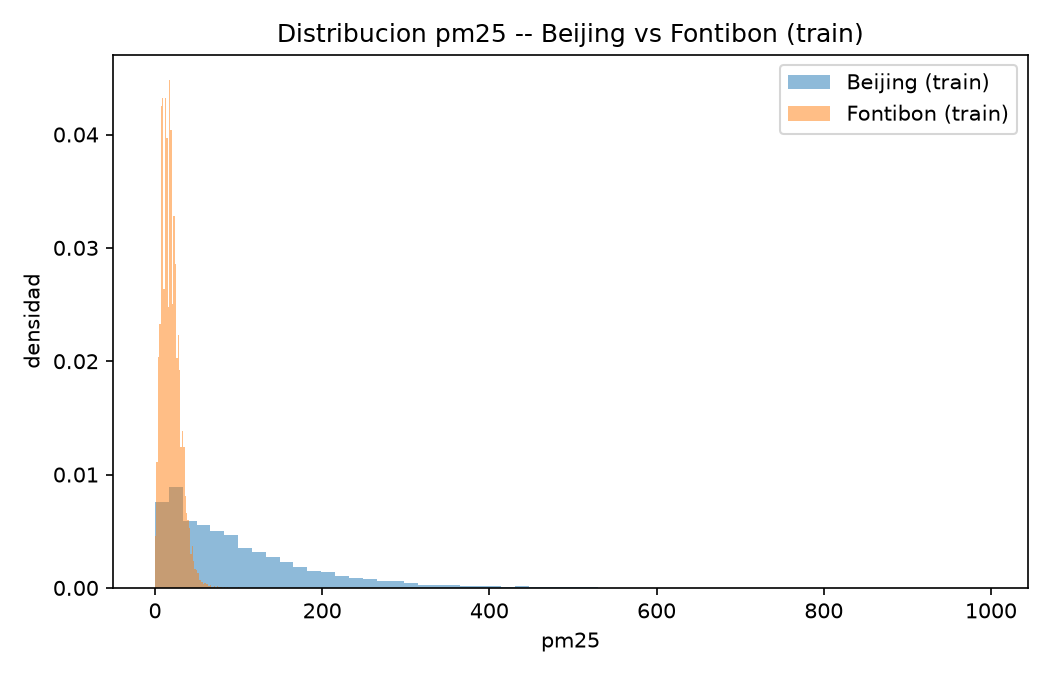

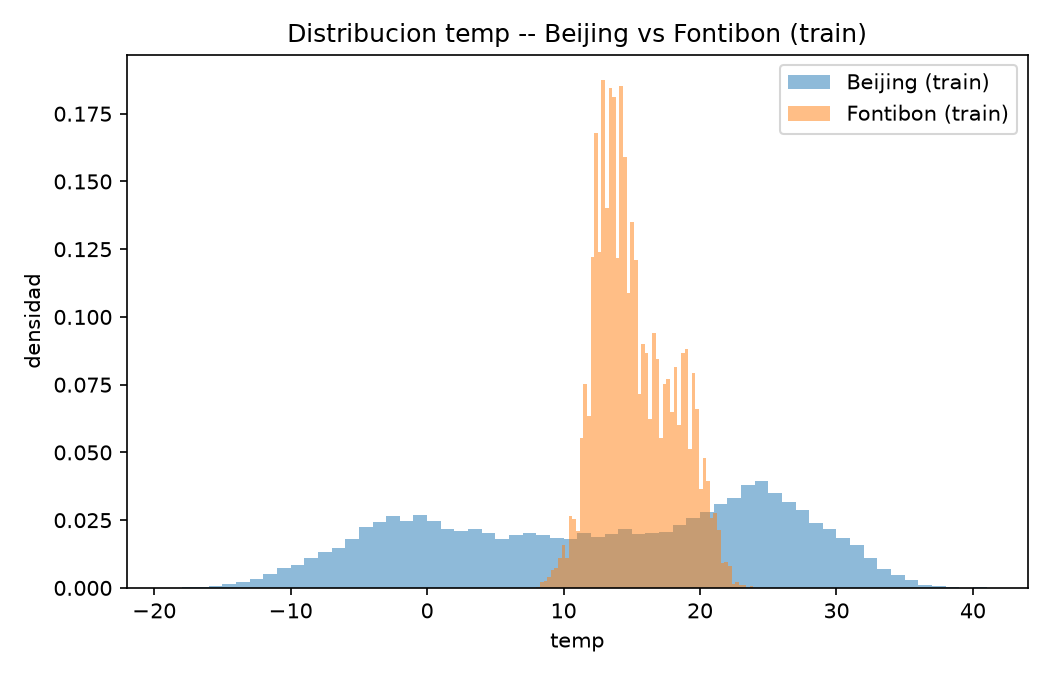

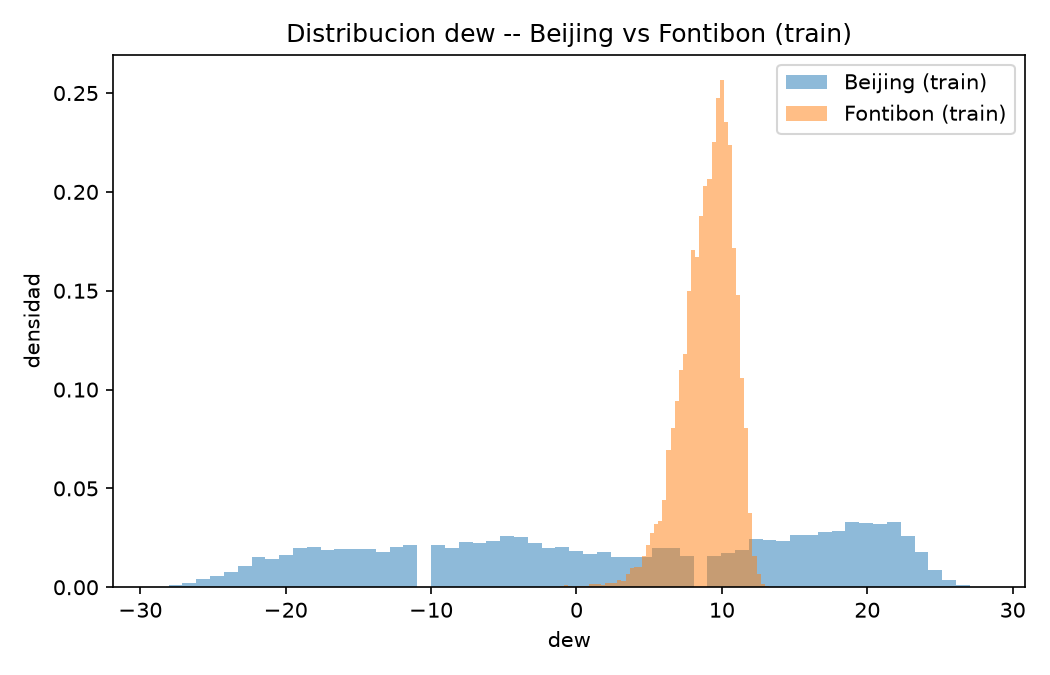

In [9]:
for var in dd["variables"]:
    fpath = OUTPUTS_DIR / "figures" / "domain_distance" / f"distribution_{var}.png"
    if fpath.exists():
        display(Image(filename=str(fpath)))

### 3.3 Autocorrelación (rezagos de 1, 24 y 168 horas)

,beijing,fontibon
lag_1h,0.962851,0.741452
lag_24h,0.393457,0.423406
lag_168h,0.012082,0.294764


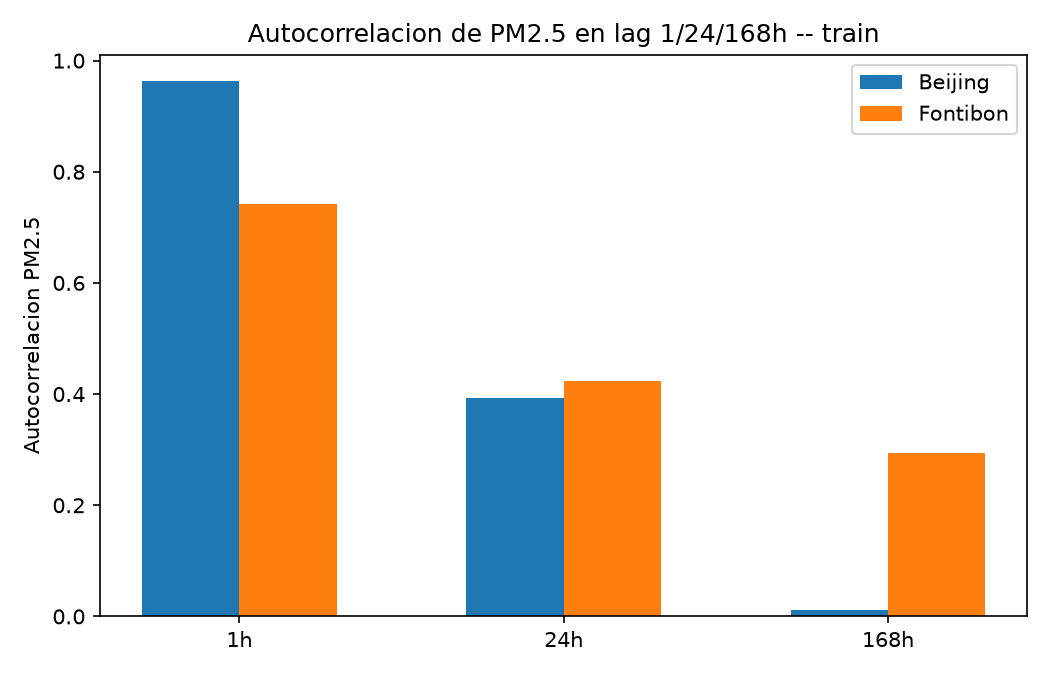

In [10]:
display(pd.DataFrame(dd["autocorrelation_pm25"]))
fpath = OUTPUTS_DIR / "figures" / "domain_distance" / "acf_pm25.png"
if fpath.exists():
    display(Image(filename=str(fpath)))

### 3.4 Perfil horario

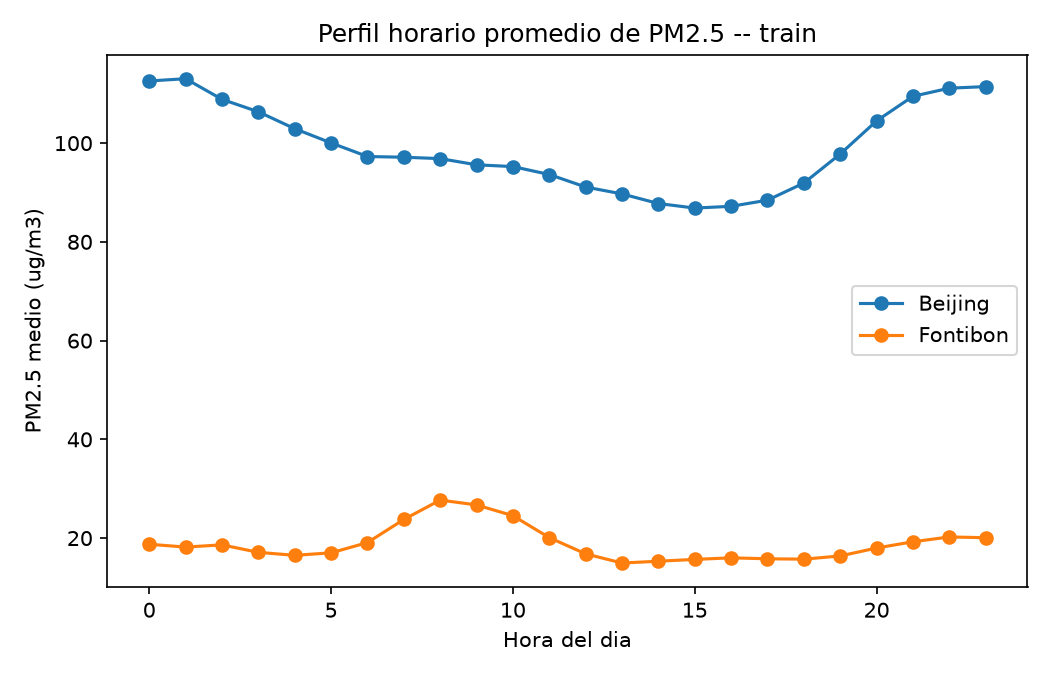

In [11]:
fpath = OUTPUTS_DIR / "figures" / "domain_distance" / "hourly_profile_pm25.png"
if fpath.exists():
    display(Image(filename=str(fpath)))

### 3.5 Distancia de Wasserstein

La media de PM2.5 en Beijing es aproximadamente 5.2 veces la de Fontibón, y su desviación estándar es cerca de 8.5 veces mayor. Al estandarizar ambas distribuciones (restar la media y dividir por la desviación, es decir, comparar solo su forma) la distancia de Wasserstein se reduce considerablemente frente a la que se obtiene con los valores crudos bajo esa misma transformación. Esto indica que, una vez removida la diferencia de escala, las distribuciones marginales de PM2.5 en los dos dominios se parecen más de lo que sugiere su nivel absoluto. Es importante no sobreinterpretar esta métrica: compara únicamente la forma de la distribución de valores, no la dinámica temporal (autocorrelación, persistencia hora a hora). Esta comparación **motiva** explorar la transferencia entre dominios como hipótesis razonable, pero **no demuestra** que Beijing y Fontibón compartan una dinámica temporal transferible, ni que la transferencia vaya a funcionar.

In [12]:
print("Wasserstein (unidades crudas):", dd["wasserstein_distance_raw_units"])
print("Wasserstein (estandarizado):", dd["wasserstein_distance_standardized"])
print()
print(dd["scale_difference_note"])

Wasserstein (unidades crudas): {'pm25': 80.16386410390457, 'temp': 8.679674412990996, 'dew': 12.202862956540452}
Wasserstein (estandarizado): {'pm25': 0.14737034753949133, 'temp': 0.2231547013849741, 'dew': 0.20110224033206459}

Beijing train PM2.5 mean 99.0 ug/m3 (std 91.7, max 994) vs. Fontibon train PM2.5 mean 18.9 ug/m3 (std 10.8, max 101). The absolute PM2.5 level and spread differ by roughly a factor of 5 between domains (this is why each domain keeps its OWN MinMax scaler — see docs/IMPLEMENTATION_ASSUMPTIONS.md). The transfer hypothesis for Config B/C/D is NOT that absolute PM2.5 levels transfer, but that TEMPORAL structure (autocorrelation, hourly profile shape) captured by the encoder/decoder may partially transfer despite the level/scale difference -- the standardized Wasserstein distance above is the quantitative counterpart of that hypothesis (comparing SHAPE of the distributions, with the level/scale difference removed by standardization).


## 4. Réplica del método sobre Beijing (R1)

### 4.1 Decisiones de implementación

El artículo no reporta todos los detalles necesarios para reconstruir la arquitectura con exactitud. Antes de fijar cualquier valor, se clasificó cada parámetro según si el artículo lo reporta explícitamente, si se puede inferir razonablemente, o si es una decisión propia del equipo; esa clasificación completa queda documentada en el proyecto.

### 4.2 Arquitectura

La arquitectura implementa el mecanismo de atención dispersa y el encoder-decoder de dos ramas que describe el artículo, y se probó exhaustivamente antes de usarse con datos reales. La configuración llamada CANDIDATE_V1 permite construir y entrenar la red, pero no es una elección final de hiperparámetros: es el punto de partida sobre el que se construyeron todos los experimentos posteriores, incluyendo R2 y la transferencia a Fontibón.

In [13]:
from src.models.stn import STNModel, build_decoder_input

CANDIDATE_V1 = dict(
    d_model=32, num_heads=4, d_ff=128, factor=3, dropout=0.10,
    n_encoder_units=2, n_decoder_layers=1,
    non_selected_fill="zero",
)

model = STNModel(**CANDIDATE_V1, seed=42)

# Build with a single synthetic batch (NOT real data) so model.summary() has shapes to show.
_batch, _lookback, _n_features = 2, 24, 3
_encoder_input = tf.random.normal((_batch, _lookback, _n_features))
_pm25_history = tf.random.normal((_batch, _lookback))
_decoder_input = build_decoder_input(_pm25_history, label_len=12, prediction_length=1)
_ = model((_encoder_input, _decoder_input), training=False)

model.summary()

total_params = sum(int(tf.size(v)) for v in model.trainable_variables)
print(f"\nCANDIDATE_V1 total trainable parameters: {total_params}")

Model: "stn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (STNEncoder)            │ ?                      │        82,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (STNDecoder)            │ ?                      │        17,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_head (OutputHead)        │ ?                      │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,425 (388.38 KB)

 Trainable params: 99,425 (388.38 KB)

 Non-trainable params: 0 (0.00 B)


CANDIDATE_V1 total trainable parameters: 99425


A continuación se ejecuta una prueba rápida de la arquitectura (forward pass, cálculo de pérdida, gradientes y un paso de optimizador) sobre datos sintéticos, solo para confirmar que el modelo construye y entrena correctamente antes de usarlo con datos reales.

In [14]:
import subprocess, sys
result = subprocess.run([sys.executable, str(PROJECT_ROOT_FROM_NOTEBOOK / "scripts" / "smoke_test_stn.py")],
                        capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)

encoder_input shape: (4, 24, 3)
decoder_input shape: (4, 13, 1)
Forward (training=False) output shape: (4, 1)
MSE loss (single synthetic batch): 1.5378190279006958
Trainable variables: 125 | missing grads: 0 | non-finite grads: 0
Weights changed after one optimizer step: 125/125

CANDIDATE_V1 total trainable parameters: 99425

Smoke test passed: forward, loss, gradients and one optimizer step all behaved as expected.
No real dataset (Beijing/Fontibon) was loaded. No training epochs were run.



### 4.3 Entrenamiento

#### Prueba de integración

Antes de lanzar un entrenamiento completo, se verificó que toda la cadena —datos, modelo, entrenamiento, evaluación— funcionara de punta a punta con una muestra pequeña y pocas épocas. Este resultado no representa el desempeño real del modelo.

In [15]:
import json as _json

print("=" * 70)
print("PILOT DE INTEGRACION -- NO RESULTADO FINAL (ya ejecutado previamente)")
print("=" * 70)
print("Beijing test 2014 NO se evalua. Fontibon NO se usa.")
print()

pilot_path = OUTPUTS_DIR / "metrics" / "R1_pilot_summary.json"
if pilot_path.exists():
    print(_json.loads(pilot_path.read_text(encoding="utf-8")))
else:
    print(f"No encontrado: {pilot_path} -- este notebook NO ejecuta entrenamientos; "
          "correr scripts/run_r1_pilot.py manualmente primero si hace falta.")

PILOT DE INTEGRACION -- NO RESULTADO FINAL (ya ejecutado previamente)
Beijing test 2014 NO se evalua. Fontibon NO se usa.

{'label': 'PILOT DE INTEGRACION -- NO RESULTADO FINAL', 'seed': 42, 'candidate': 'CANDIDATE_V1', 'total_trainable_parameters': 99681, 'train_windows_used': 4096, 'validation_windows_used': 1024, 'epochs_run': 5, 'history': [{'epoch': 1, 'train_loss': 0.1999163119471632, 'val_loss': 0.01812276239591757, 'train_rmse_scaled': 0.13051210630858961, 'val_rmse_scaled': 0.13462080966892737, 'learning_rate': 9.999999747378752e-05, 'gradient_global_norm_mean': 5.234083270654082, 'gradient_global_norm_max': 33.584896087646484, 'gradient_global_norm_std': 4.777428833031937, 'epoch_time_seconds': 26.4883394241333}, {'epoch': 2, 'train_loss': 0.0930063818814233, 'val_loss': 0.007982058677129863, 'train_rmse_scaled': 0.08370028157925778, 'val_rmse_scaled': 0.08934236776093335, 'learning_rate': 9.999999747378752e-05, 'gradient_global_norm_mean': 2.206858658697456, 'gradient_global

#### Entrenamiento completo

El entrenamiento definitivo de R1 se hizo sobre las 29.237 ventanas de entrenamiento y 2.841 de validación, sin submuestreo, con un máximo de 200 épocas y parada anticipada (paciencia de 15 épocas sobre la pérdida de validación). Este entrenamiento ya se ejecutó fuera de este notebook; aquí solo se leen y muestran sus resultados guardados.

In [16]:
import json as _json

summary_path = OUTPUTS_DIR / "metrics" / "R1_development_seed42_summary.json"

if not summary_path.exists():
    print(f"No encontrado: {summary_path}")
    print("Este notebook NO entrena automaticamente -- correr")
    print("'python scripts/run_r1_development.py 42' manualmente primero (puede tardar horas).")
else:
    r1_dev_summary = _json.loads(summary_path.read_text(encoding="utf-8"))
    print("Estado:", r1_dev_summary["status"])
    print("Beijing test 2014 evaluado:", r1_dev_summary["beijing_test_2014_evaluated"])
    print("Fontibon usado:", r1_dev_summary["fontibon_used"])
    print()
    print("Epocas totales:", r1_dev_summary["total_epochs"], "| best epoch:", r1_dev_summary["best_epoch"],
          "| stopping epoch:", r1_dev_summary["stopping_epoch"])
    print("Tiempo total (s):", round(r1_dev_summary["total_training_time_seconds"], 1))
    print()
    print("Train (ug/m3):", r1_dev_summary["train_metrics_ug_m3"])
    print("Validation (ug/m3):", r1_dev_summary["validation_metrics_ug_m3"])
    print("Persistence validation (ug/m3):", r1_dev_summary["persistence_validation_metrics_ug_m3"])
    print()
    print("Clasificacion descriptiva:", r1_dev_summary["descriptive_classification_vs_persistence"])
    print()
    print("Distribucion target validation (ug/m3):", r1_dev_summary["validation_target_distribution_ug_m3"])
    print("Diagnostico de residuales (validation, ug/m3):", r1_dev_summary["validation_residual_diagnostics_ug_m3"])

Estado: development_validation_only
Beijing test 2014 evaluado: False
Fontibon usado: False

Epocas totales: 58 | best epoch: 43 | stopping epoch: 58
Tiempo total (s): 46749.7

Train (ug/m3): {'RMSE': 23.436776573759268, 'MAE': 12.796827863895865, 'R2': 0.9349129966670854}
Validation (ug/m3): {'RMSE': 21.122482984827, 'MAE': 12.675257302429927, 'R2': 0.9473656870387863}
Persistence validation (ug/m3): {'RMSE': 22.85815495949004, 'MAE': 13.212601196761703, 'R2': 0.9383601794562767}

Clasificacion descriptiva: A: el modelo converge y mejora claramente a la referencia

Distribucion target validation (ug/m3): {'p50': 67.0, 'p75': 142.0, 'p90': 234.0, 'p95': 290.0, 'p99': 390.7999999999997, 'max': 480.0}
Diagnostico de residuales (validation, ug/m3): {'bias_mean': -2.0857167570828468, 'std': 21.019254816799045, 'p05': -31.403913497924805, 'p25': -9.825531005859375, 'p50': -1.5328292846679688, 'p75': 4.612640380859375, 'p95': 26.896728515625}


#### Curvas de entrenamiento

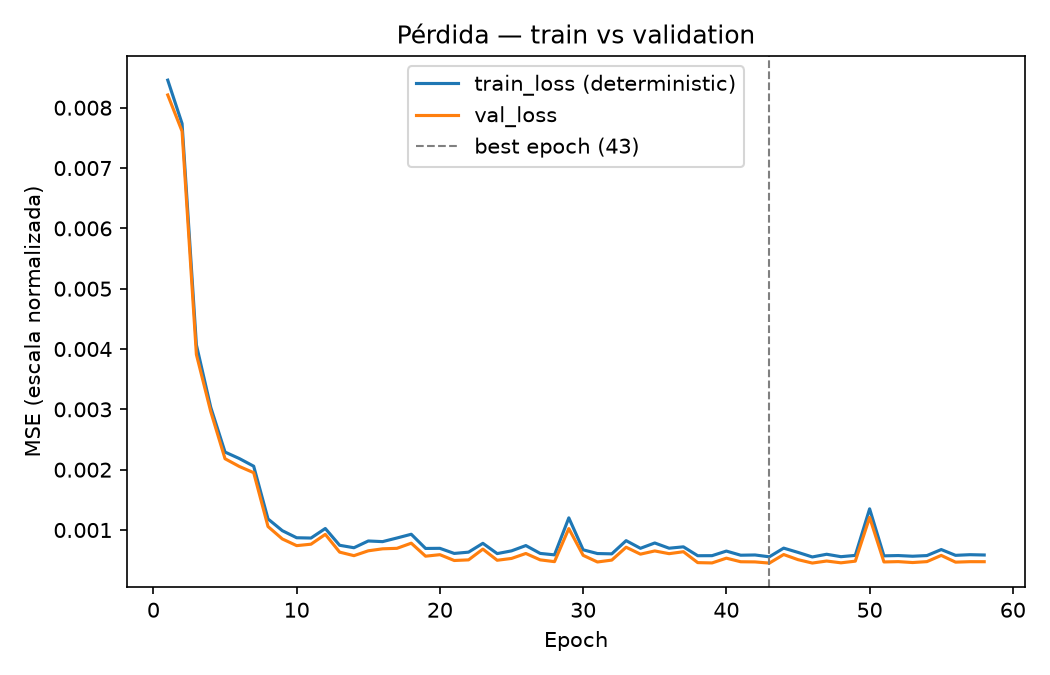

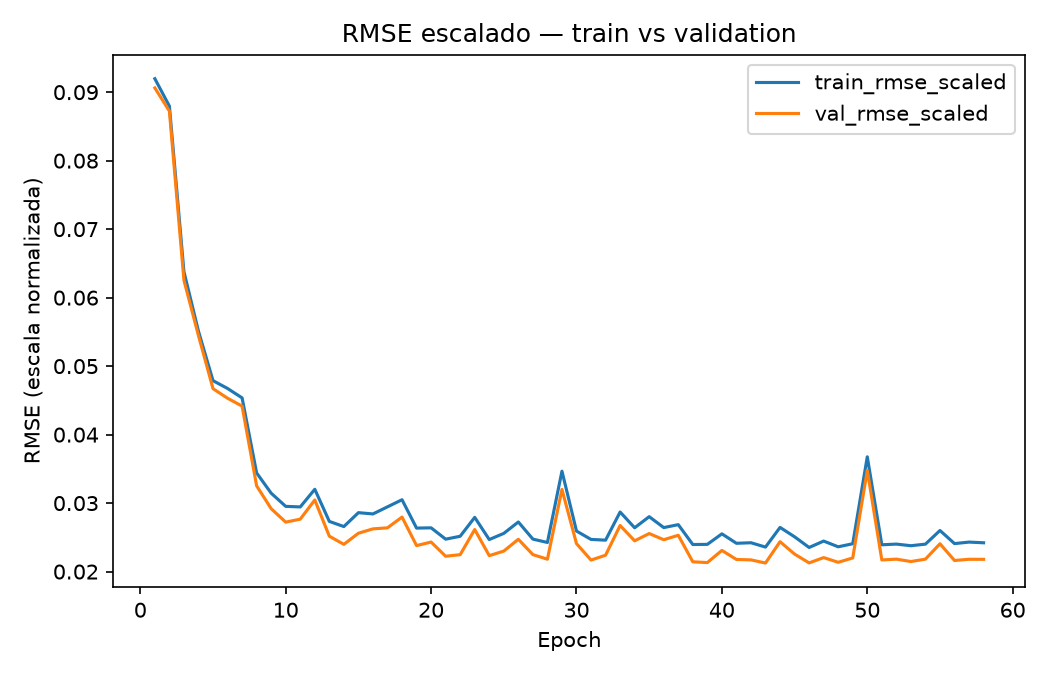

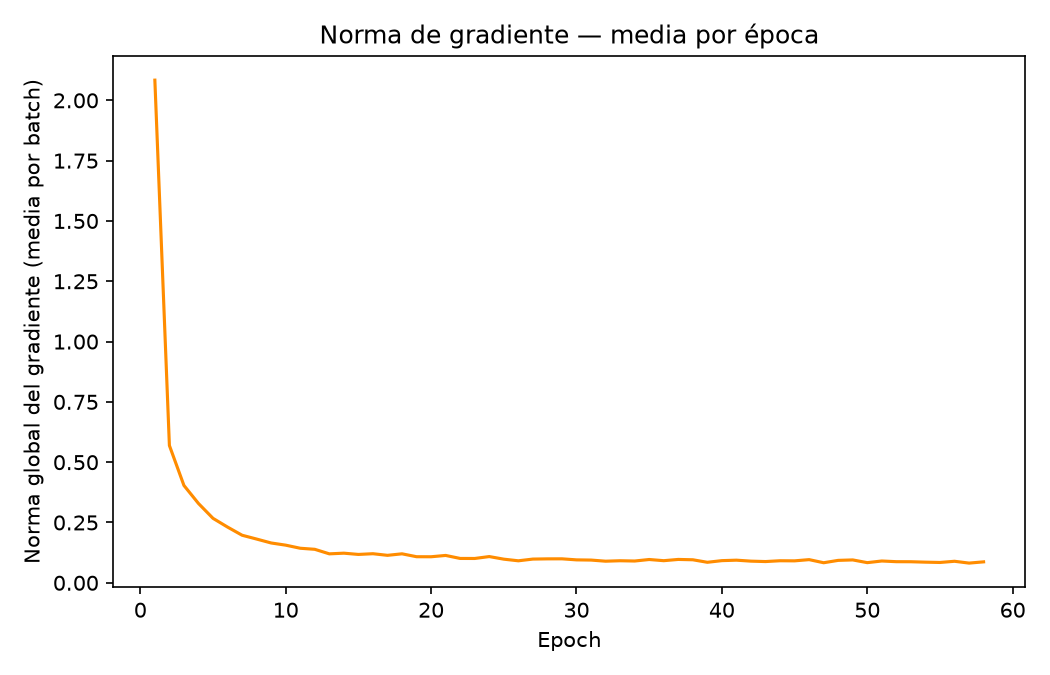

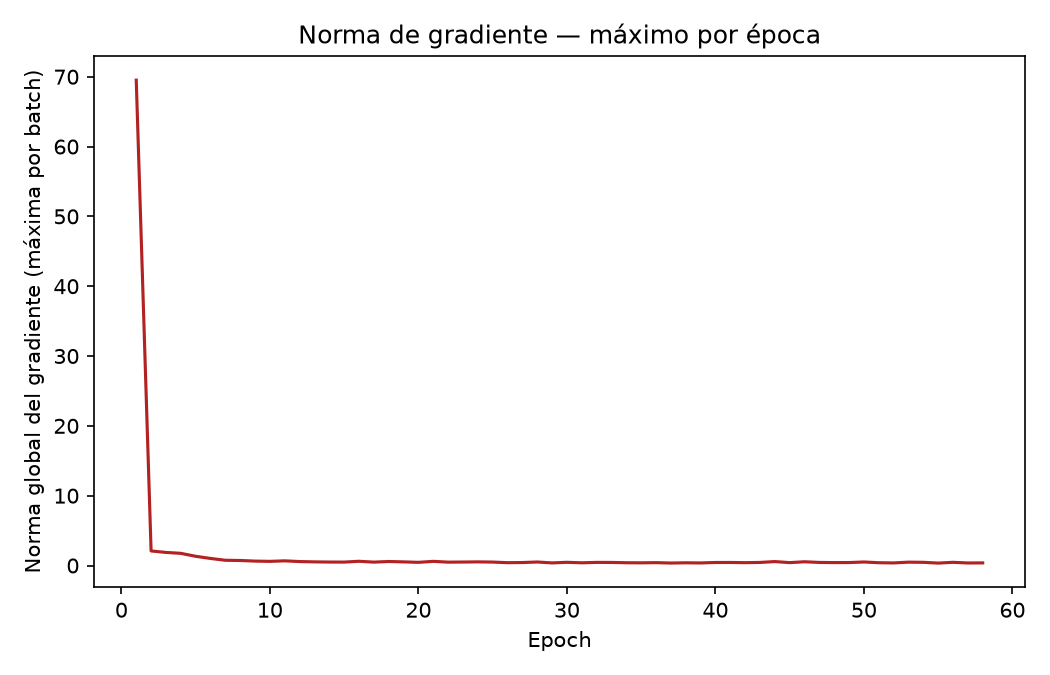

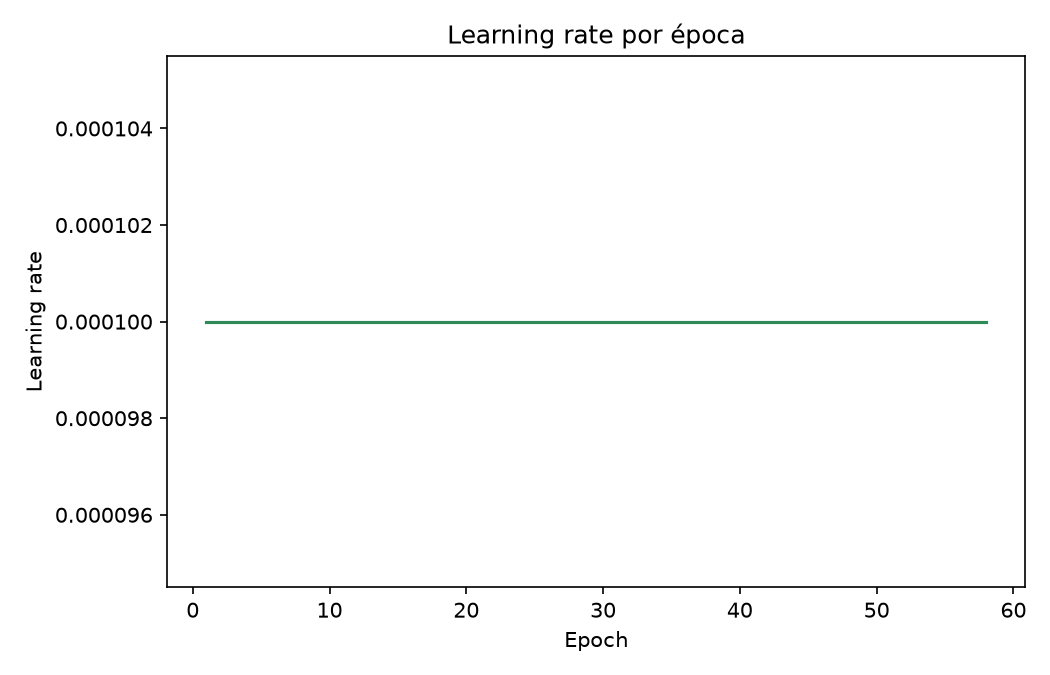

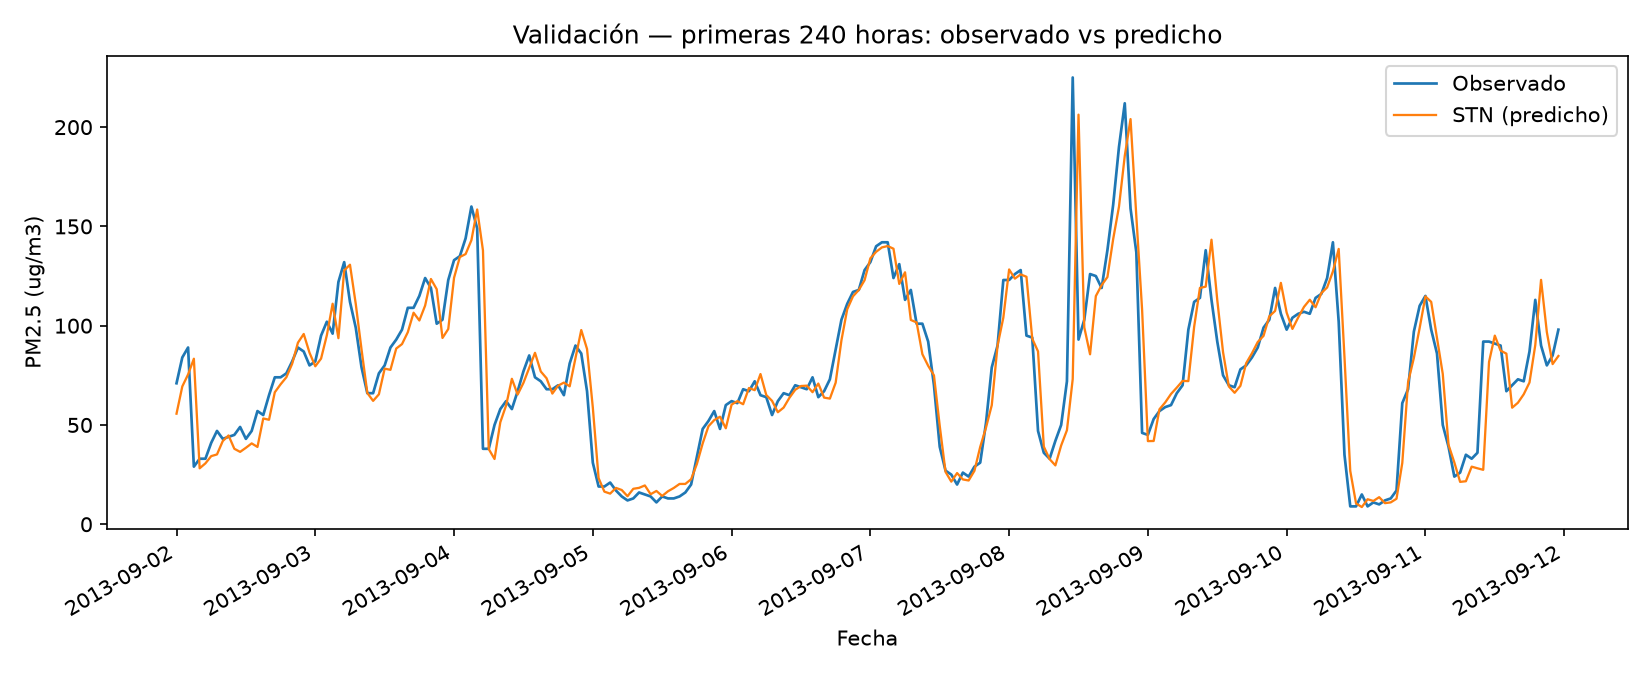

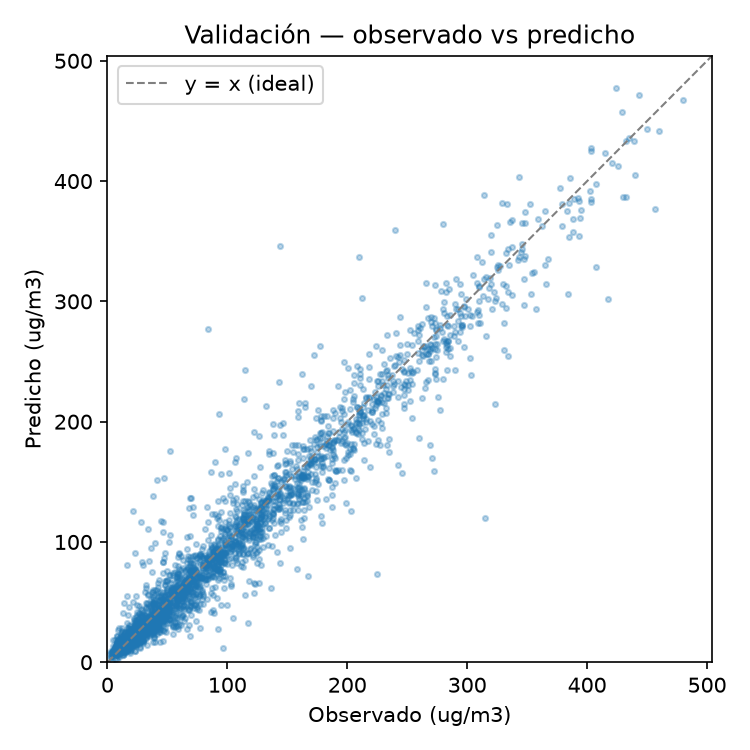

In [17]:
from IPython.display import Image, display

figures_dir = OUTPUTS_DIR / "figures" / "R1_development_seed42"  # portable: not the absolute path baked into the JSON
for fname in [
    "loss_train_vs_validation.png",
    "rmse_scaled_train_vs_validation.png",
    "gradient_norm_mean.png",
    "gradient_norm_max.png",
    "learning_rate.png",
    "validation_predictions_vs_real.png",
    "validation_scatter_real_vs_pred.png",
]:
    fpath = figures_dir / fname
    if fpath.exists():
        display(Image(filename=str(fpath)))

#### Estabilidad entre semillas

Para confiar en que un resultado no depende de una inicialización afortunada, el mismo entrenamiento se repitió con tres semillas (42, 123 y 2026), cada una partiendo de pesos iniciales independientes. Ninguna semilla se presenta como la mejor: lo relevante es qué tan parecidas son entre sí.

In [18]:
import json as _json

r1_comparison = _json.loads((OUTPUTS_DIR / "metrics" / "R1_development_seed_comparison.json").read_text(encoding="utf-8"))

print("Seed | best_ep | stop_ep | train_RMSE | val_RMSE | val_MAE | val_R2")
for r in r1_comparison["rows"]:
    print(f"{r['seed']:5d}| {r['best_epoch']:7d} | {r['stopping_epoch']:7d} | "
          f"{r['train_RMSE']:10.3f} | {r['val_RMSE']:8.3f} | {r['val_MAE']:7.3f} | {r['val_R2']:.4f}")

stats = r1_comparison["validation_stats"]
print(f"\nValidation RMSE: {stats['val_RMSE_mean']:.3f} +/- {stats['val_RMSE_std']:.3f}")
print(f"Validation MAE:  {stats['val_MAE_mean']:.3f} +/- {stats['val_MAE_std']:.3f}")
print(f"Validation R2:   {stats['val_R2_mean']:.4f} +/- {stats['val_R2_std']:.4f}")

persistence = r1_comparison["persistence_validation_metrics_ug_m3"]
print(f"\nPersistence (referencia, no depende de semilla): RMSE={persistence['RMSE']:.3f} "
      f"MAE={persistence['MAE']:.3f} R2={persistence['R2']:.4f}")

print(f"\nDiagnostico de estabilidad: {r1_comparison['stability_diagnostics']}")
print(f"\nBeijing test 2014 evaluado: {r1_comparison['beijing_test_2014_evaluated']}")
print(f"Fontibon usado: {r1_comparison['fontibon_used']}")

Seed | best_ep | stop_ep | train_RMSE | val_RMSE | val_MAE | val_R2
   42|      43 |      58 |     23.437 |   21.122 |  12.675 | 0.9474
  123|      72 |      87 |     22.565 |   20.781 |  12.431 | 0.9491
 2026|      52 |      67 |     23.303 |   21.242 |  12.893 | 0.9468

Validation RMSE: 21.048 +/- 0.240
Validation MAE:  12.666 +/- 0.231
Validation R2:   0.9477 +/- 0.0012

Persistence (referencia, no depende de semilla): RMSE=22.858 MAE=13.213 R2=0.9384

Diagnostico de estabilidad: {'n_seeds': 3, 'seeds': [42, 123, 2026], 'val_RMSE_coefficient_of_variation': 0.01138162564575687, 'best_epoch_spread': 29, 'all_seeds_beat_persistence': True, 'note': "Descriptive only. No seed is presented as 'the' result; all three form the stability report. Beijing test 2014 not evaluated for any seed. Fontibon not used."}

Beijing test 2014 evaluado: False
Fontibon usado: False


Las tres semillas superan de forma consistente a una referencia ingenua —predecir que el valor de la hora siguiente es igual al actual—: RMSE de validación de 21.05 ± 0.24 µg/m³ frente a 22.86 µg/m³ de esa referencia, con una dispersión baja entre semillas (poco más del 1% del RMSE medio). La época en la que cada semilla alcanza su mejor resultado varía más (43, 72 y 52) que el resultado final, lo cual es normal con parada anticipada y no indica inestabilidad del modelo.

### 4.4 Comparación contra el artículo

El conjunto de prueba de 2014 se evaluó una única vez, después de congelar por completo la arquitectura, el preprocesamiento y los hiperparámetros, sin haber consultado antes ningún resultado sobre ese conjunto. Para cada semilla se cargó el modelo ya entrenado y se calcularon las métricas por inferencia pura, sin entrenar ni ajustar nada.

El artículo reporta RMSE=19.04, MAE=11.13 y R²=0.937 para el horizonte de una hora. La comparación que sigue es descriptiva, no una réplica exacta: la arquitectura usada aquí es más reducida que la del artículo (2 bloques de encoder y 1 de decoder, frente a 3 y 2), la validación se hizo de forma cronológica en vez de aleatoria, y el tratamiento de datos faltantes y el escalado siguen un protocolo propio que el artículo no detalla lo suficiente como para replicarlo exactamente.

In [19]:
r1_test_summary = _json.loads((OUTPUTS_DIR / "metrics" / "R1_test_final_summary.json").read_text(encoding="utf-8"))

print("Ventanas de test:", r1_test_summary["n_test_windows"])
print()
print("Por semilla (ug/m3):")
for seed, m in r1_test_summary["per_seed_test_metrics_ug_m3"].items():
    print(f"  seed {seed}: RMSE={m['RMSE']:.3f} MAE={m['MAE']:.3f} R2={m['R2']:.4f}")

agg = r1_test_summary["aggregate_test_metrics_ug_m3"]
print(f"\nTest RMSE: {agg['RMSE_mean']:.3f} +/- {agg['RMSE_std']:.3f}")
print(f"Test MAE:  {agg['MAE_mean']:.3f} +/- {agg['MAE_std']:.3f}")
print(f"Test R2:   {agg['R2_mean']:.4f} +/- {agg['R2_std']:.4f}")

persistence_test = r1_test_summary["persistence_test_metrics_ug_m3"]
print(f"\nPersistence (test, sanity check): RMSE={persistence_test['RMSE']:.3f} "
      f"MAE={persistence_test['MAE']:.3f} R2={persistence_test['R2']:.4f}")

paper = r1_test_summary["paper_reference_zhang_zhang_2023"]
diff = r1_test_summary["descriptive_difference_vs_paper_reference"]
print(f"\nReferencia Zhang & Zhang (2023): {paper}")
print(f"Diferencia descriptiva (nuestro - paper): {diff}")

print(f"\nEntrenamiento realizado en esta evaluacion: {r1_test_summary['training_performed']}")
print(f"Arquitectura modificada tras ver test: {r1_test_summary['architecture_modified_after_seeing_test']}")
print(f"Semilla elegida mirando test: {r1_test_summary['seed_selected_based_on_test']}")
print(f"Fontibon usado: {r1_test_summary['fontibon_used']}")

Ventanas de test: 8487

Por semilla (ug/m3):
  seed 42: RMSE=20.692 MAE=11.744 R2=0.9508
  seed 123: RMSE=21.207 MAE=11.780 R2=0.9483
  seed 2026: RMSE=21.481 MAE=12.060 R2=0.9469

Test RMSE: 21.127 +/- 0.400
Test MAE:  11.862 +/- 0.173
Test R2:   0.9487 +/- 0.0019

Persistence (test, sanity check): RMSE=22.024 MAE=11.915 R2=0.9442

Referencia Zhang & Zhang (2023): {'RMSE': 19.04, 'MAE': 11.13, 'R2': 0.937}
Diferencia descriptiva (nuestro - paper): {'RMSE_diff_ours_minus_paper': 2.0867075756781936, 'MAE_diff_ours_minus_paper': 0.7315694544188993, 'R2_diff_ours_minus_paper': 0.01165165418768177}

Entrenamiento realizado en esta evaluacion: False
Arquitectura modificada tras ver test: False
Semilla elegida mirando test: False
Fontibon usado: False


Las siguientes figuras muestran las predicciones frente a los valores reales y la dispersión de resultados entre semillas.

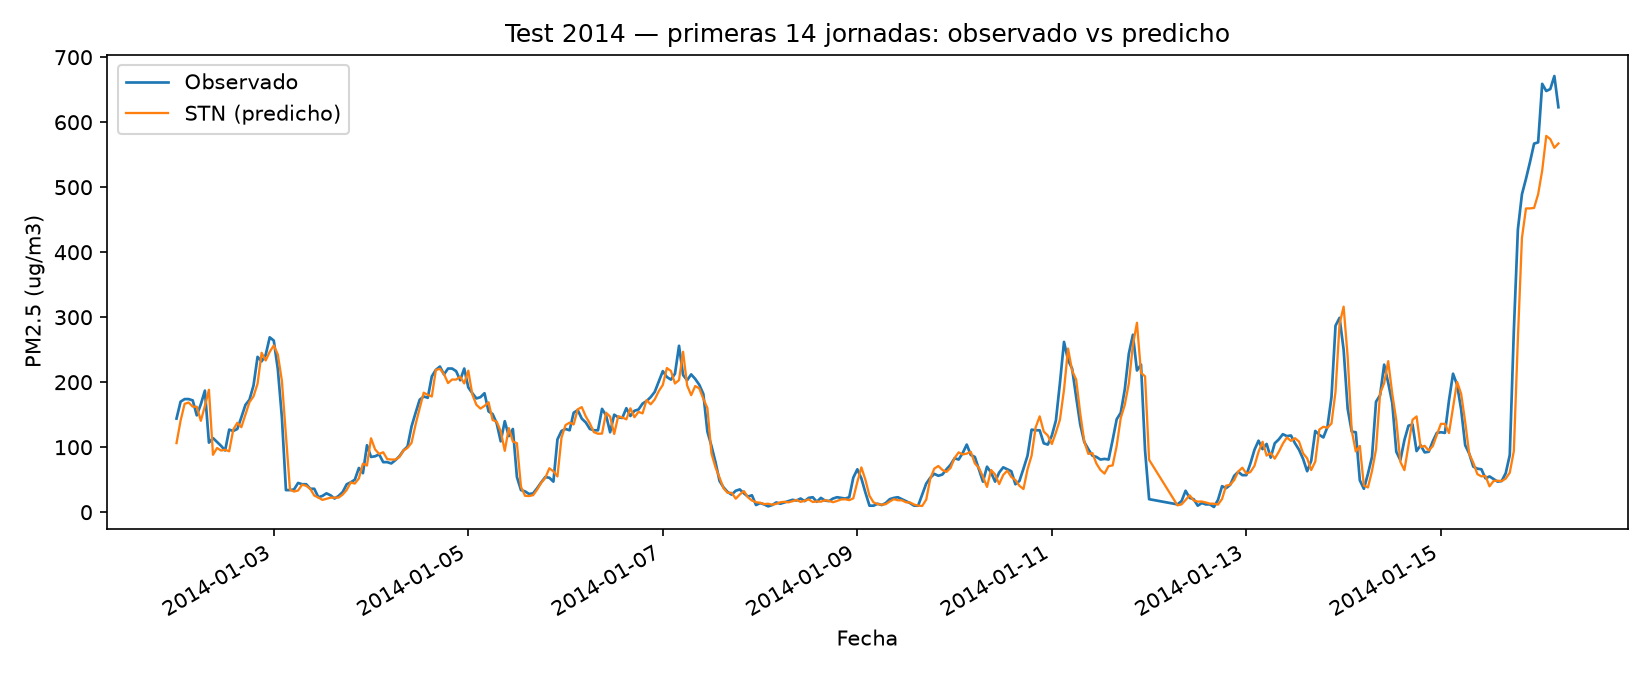

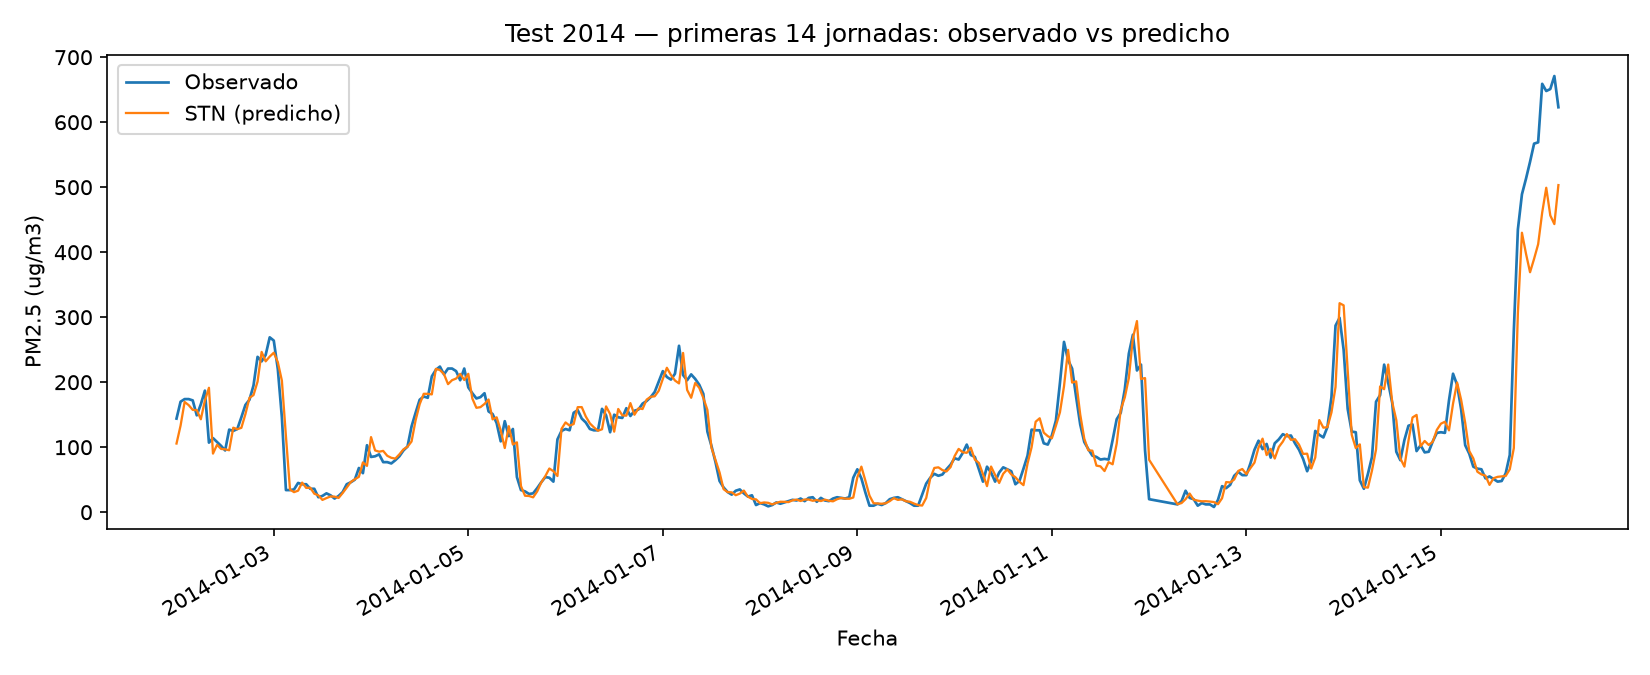

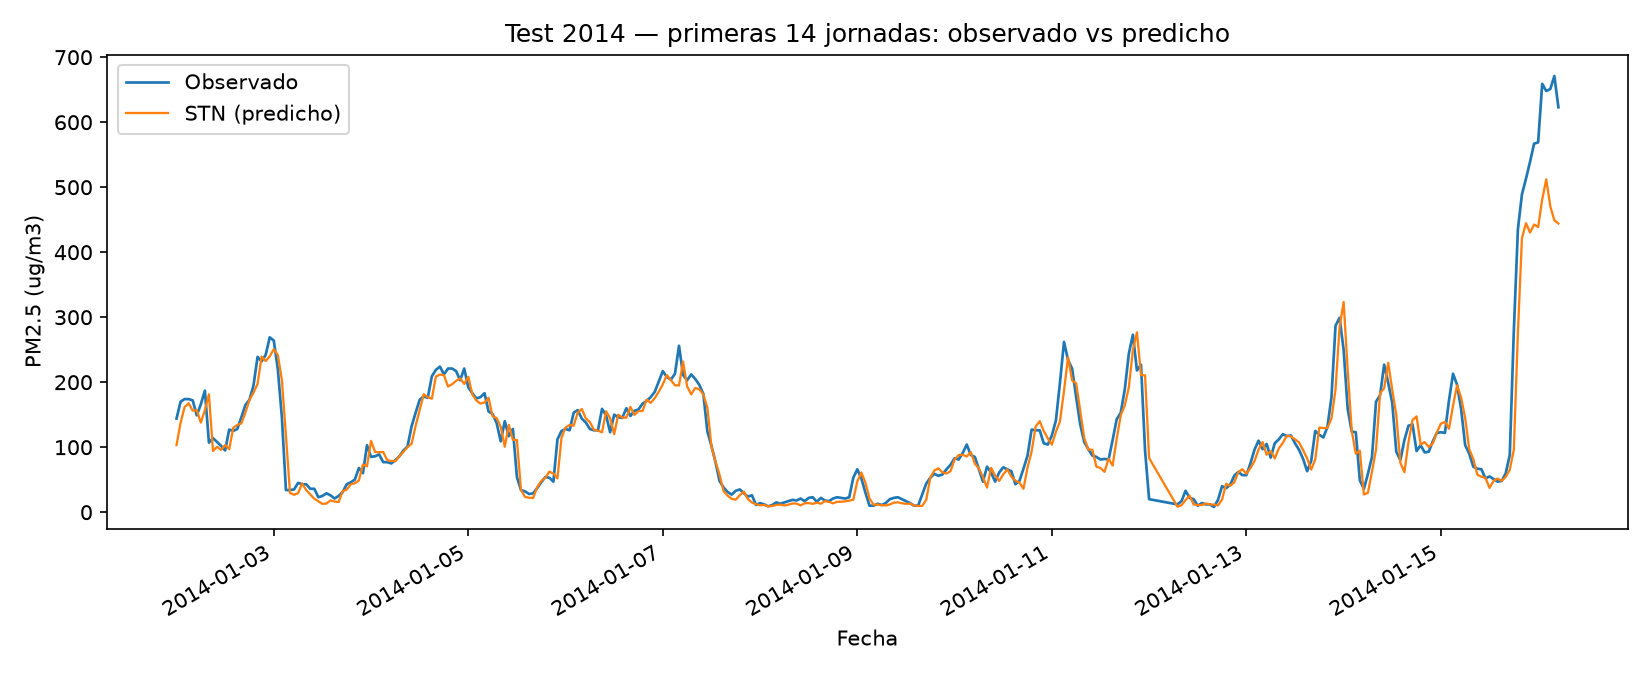

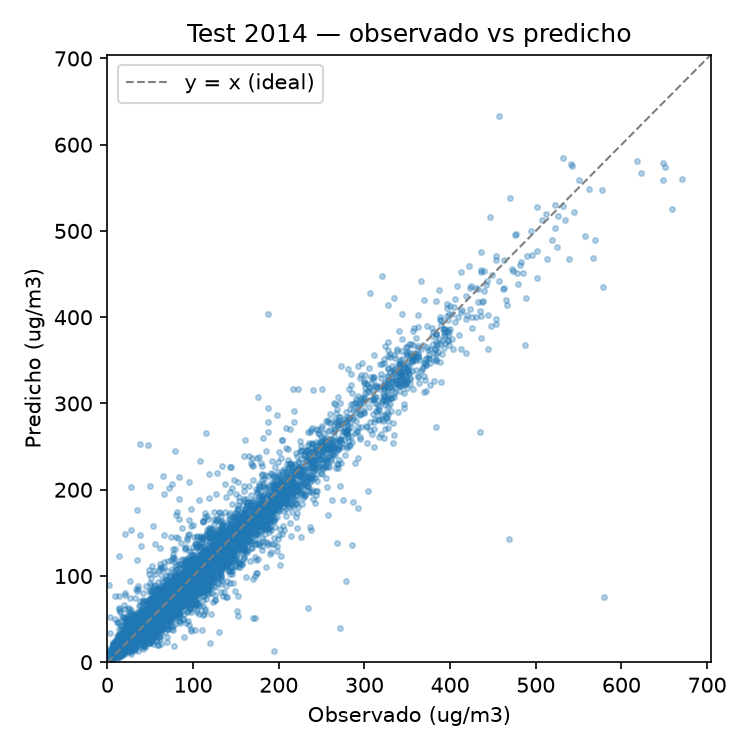

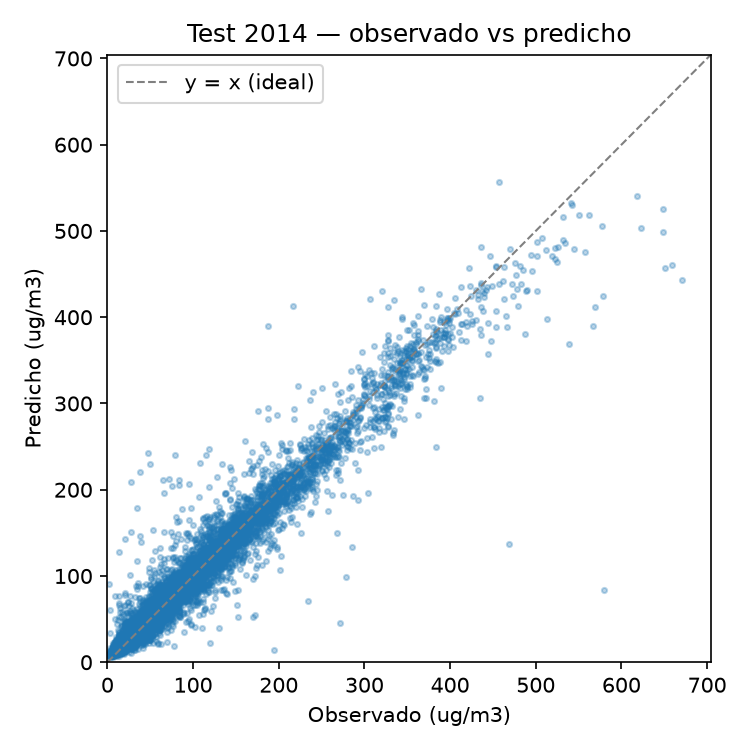

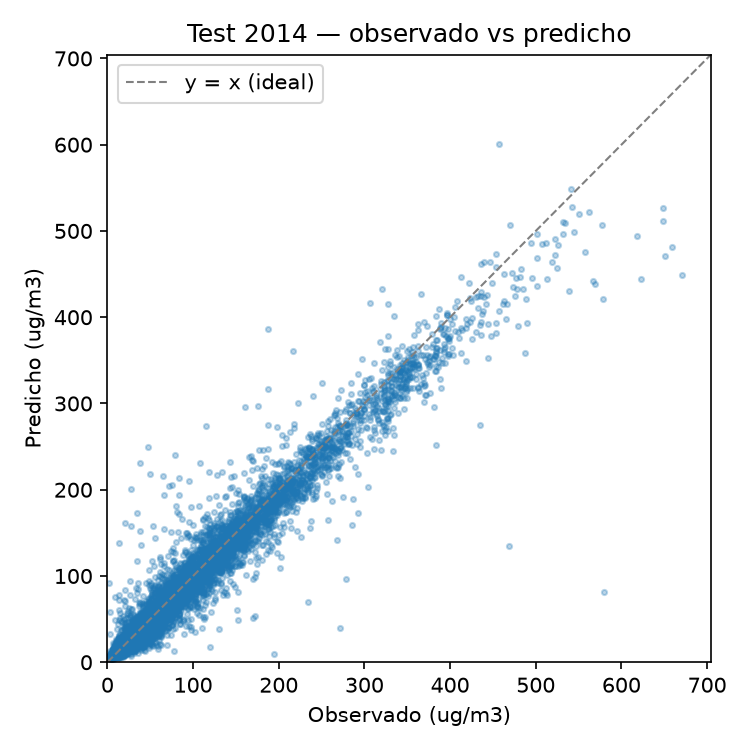

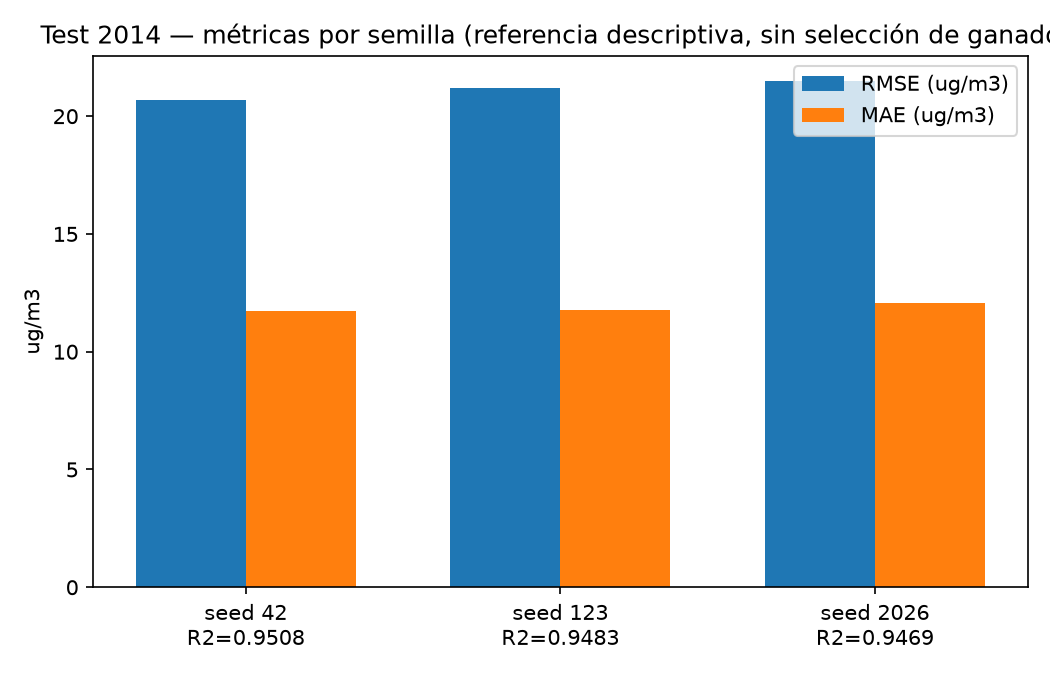

In [20]:
for fname in [
    "test_predictions_vs_real_seed42.png", "test_predictions_vs_real_seed123.png", "test_predictions_vs_real_seed2026.png",
    "test_scatter_seed42.png", "test_scatter_seed123.png", "test_scatter_seed2026.png",
    "test_metrics_across_seeds.png",
]:
    fpath = OUTPUTS_DIR / "figures" / "R1_test_final" / fname
    if fpath.exists():
        display(Image(filename=str(fpath)))

#### Conclusión de R1

Las tres semillas convergen a resultados de prueba consistentes (RMSE 21.13 ± 0.40 µg/m³, R² 0.9487 ± 0.0019), superan claramente a la referencia ingenua (RMSE=22.02) y quedan razonablemente cerca del resultado publicado, incluso con un R² ligeramente superior (0.9487 frente a 0.937) — aunque, como ya se explicó, no es una comparación perfectamente equivalente. Con esto, R1 queda cerrado: ni la arquitectura, ni los hiperparámetros, ni los checkpoints se modifican de aquí en adelante.

## 5. Beijing como modelo fuente (R2)

Para transferir lo aprendido en Beijing hacia Fontibón, primero hay que preentrenar un modelo sobre Beijing usando únicamente las variables que ambos dominios comparten: PM2.5, temperatura y punto de rocío. A esto se le llama R2, y conviene no confundirlo con una segunda réplica del artículo: su resultado no se compara contra el RMSE publicado, porque su propósito es distinto — producir pesos que sirvan como punto de partida para Fontibón.

La arquitectura es idéntica a la de R1 (CANDIDATE_V1); lo único que cambia es la capa de entrada, que ahora recibe 3 variables en lugar de 11. Por eso los pesos de R1 no se reutilizan directamente en R2: la forma de esa primera capa ya no coincide. El entrenamiento usa el mismo split cronológico que R1 y las mismas tres semillas, cada una entrenada de forma independiente.

In [21]:
import json
import pandas as pd

r2_comparison_path = OUTPUTS_DIR / "metrics" / "R2_source_seed_comparison.json"
r2_comparison = json.loads(r2_comparison_path.read_text(encoding="utf-8"))

r2_table = pd.DataFrame(r2_comparison["rows"])[
    ["seed", "best_epoch", "stopping_epoch", "train_RMSE", "val_RMSE", "val_MAE", "val_R2",
     "bias", "training_time_seconds", "gradient_norm_initial", "gradient_norm_final",
     "gradient_norm_max", "compatible_from_checkpoint"]
]
display(r2_table)

stats = r2_comparison["validation_stats"]
print(f"Validation RMSE: {stats['val_RMSE_mean']:.3f} +/- {stats['val_RMSE_std']:.3f} ug/m3")
print(f"Validation MAE:  {stats['val_MAE_mean']:.3f} +/- {stats['val_MAE_std']:.3f} ug/m3")
print(f"Validation R2:   {stats['val_R2_mean']:.4f} +/- {stats['val_R2_std']:.4f}")
print(f"Todos los checkpoints compatibles con target Fontibon (3 canales): "
      f"{r2_comparison['stability_diagnostics']['all_checkpoints_compatible_with_fontibon_shaped_target']}")

,seed,best_epoch,stopping_epoch,train_RMSE,val_RMSE,val_MAE,val_R2,bias,training_time_seconds,gradient_norm_initial,gradient_norm_final,gradient_norm_max,compatible_from_checkpoint
0,42,54,69,23.587373,21.140981,13.006536,0.947273,1.634119,13262.689090,2.075958,0.083191,71.394203,True
1,123,58,73,23.318269,20.970685,12.543870,0.948119,1.329435,14583.191252,1.952919,0.075087,59.925697,True
2,2026,58,73,23.294177,21.068044,12.646218,0.947637,-0.207257,13899.950639,1.266497,0.062621,24.336409,True


Validation RMSE: 21.060 +/- 0.085 ug/m3
Validation MAE:  12.732 +/- 0.243 ug/m3
Validation R2:   0.9477 +/- 0.0004
Todos los checkpoints compatibles con target Fontibon (3 canales): True


Las siguientes curvas muestran la evolución de la pérdida, el RMSE y la norma del gradiente por semilla, además de la comparación agregada entre las tres.

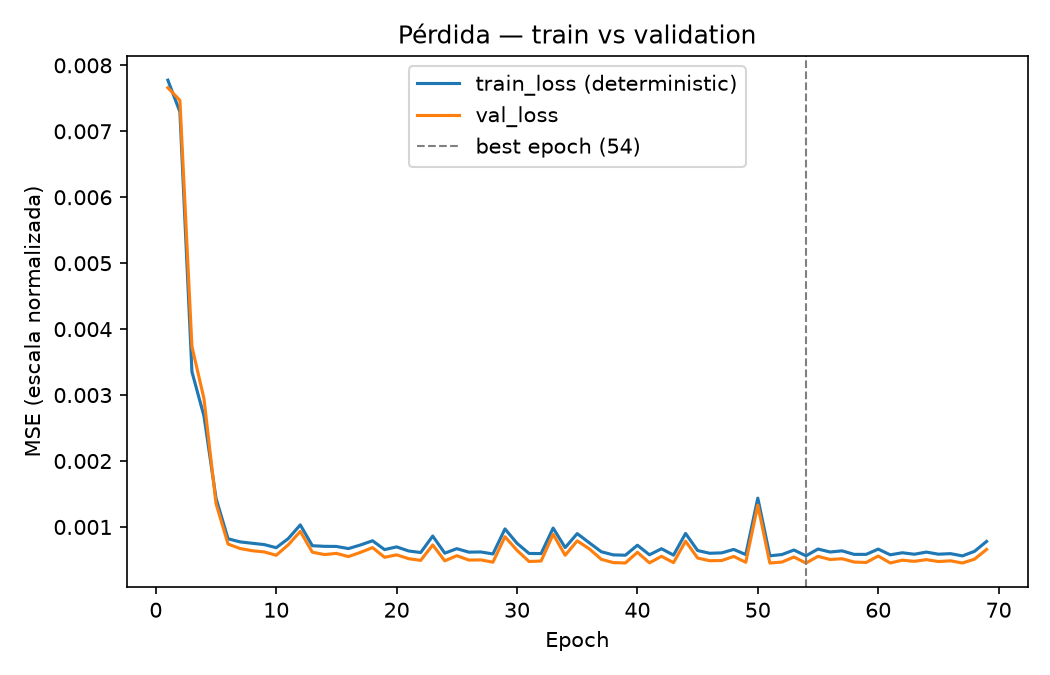

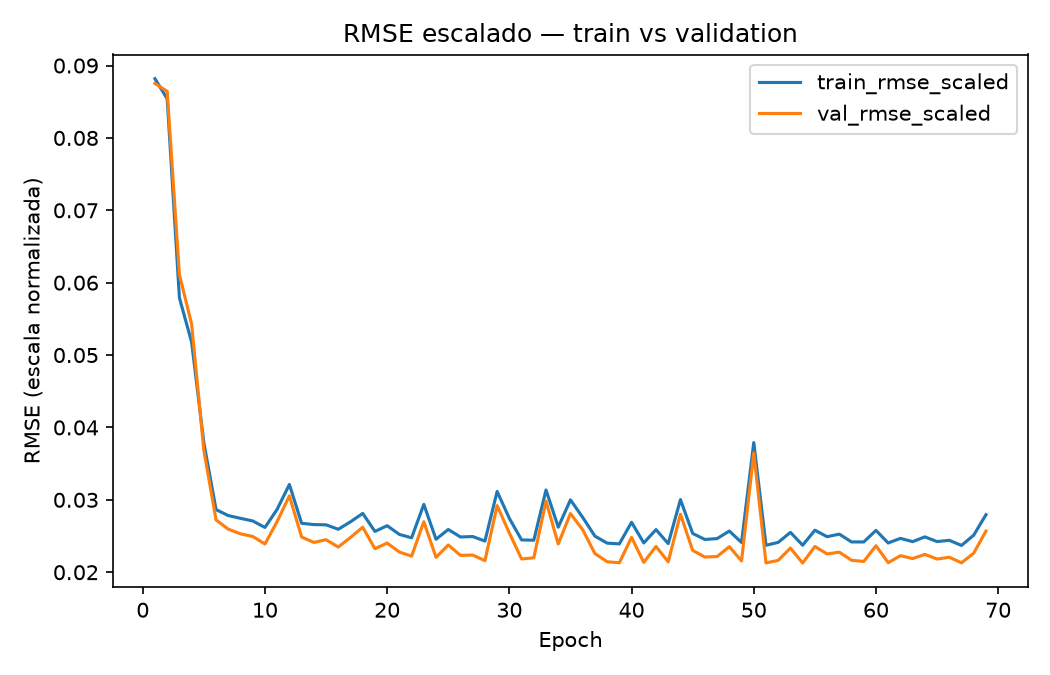

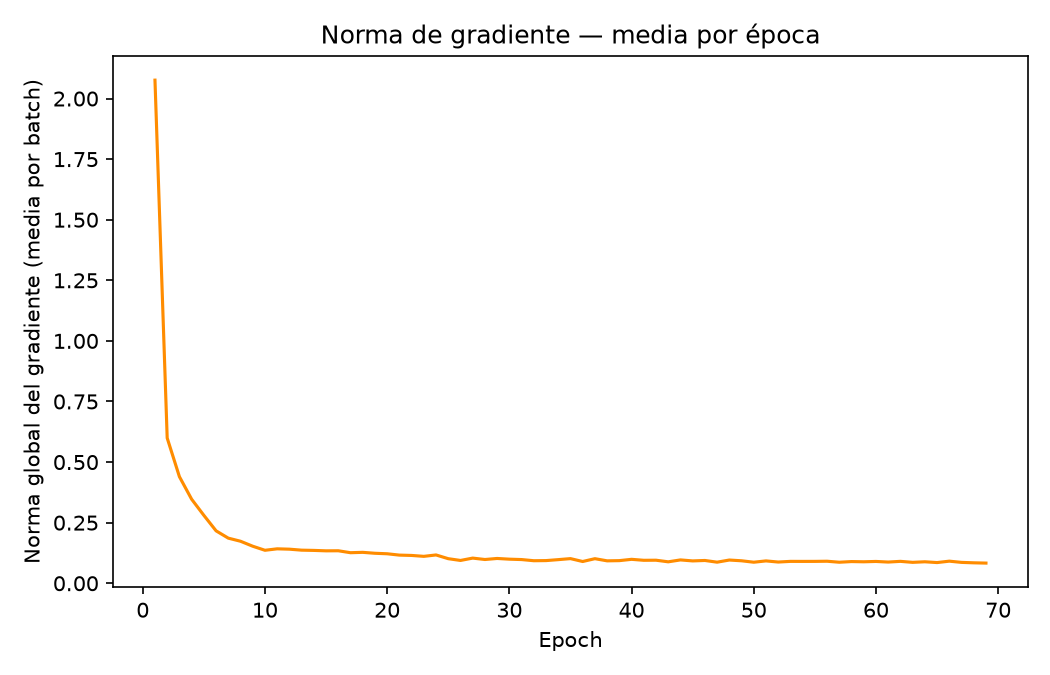

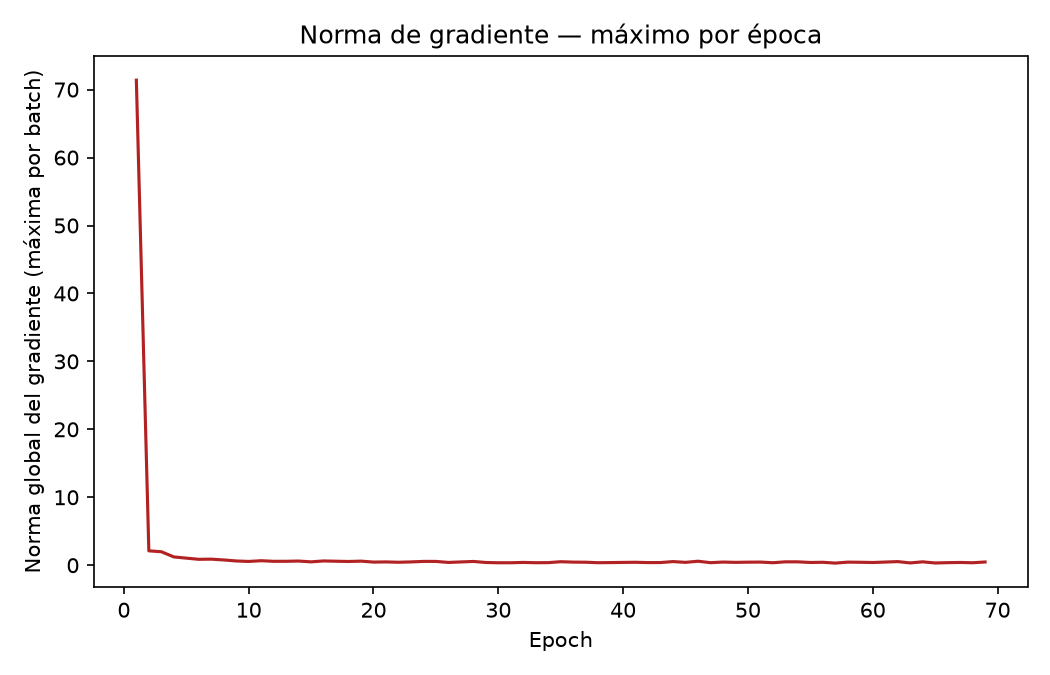

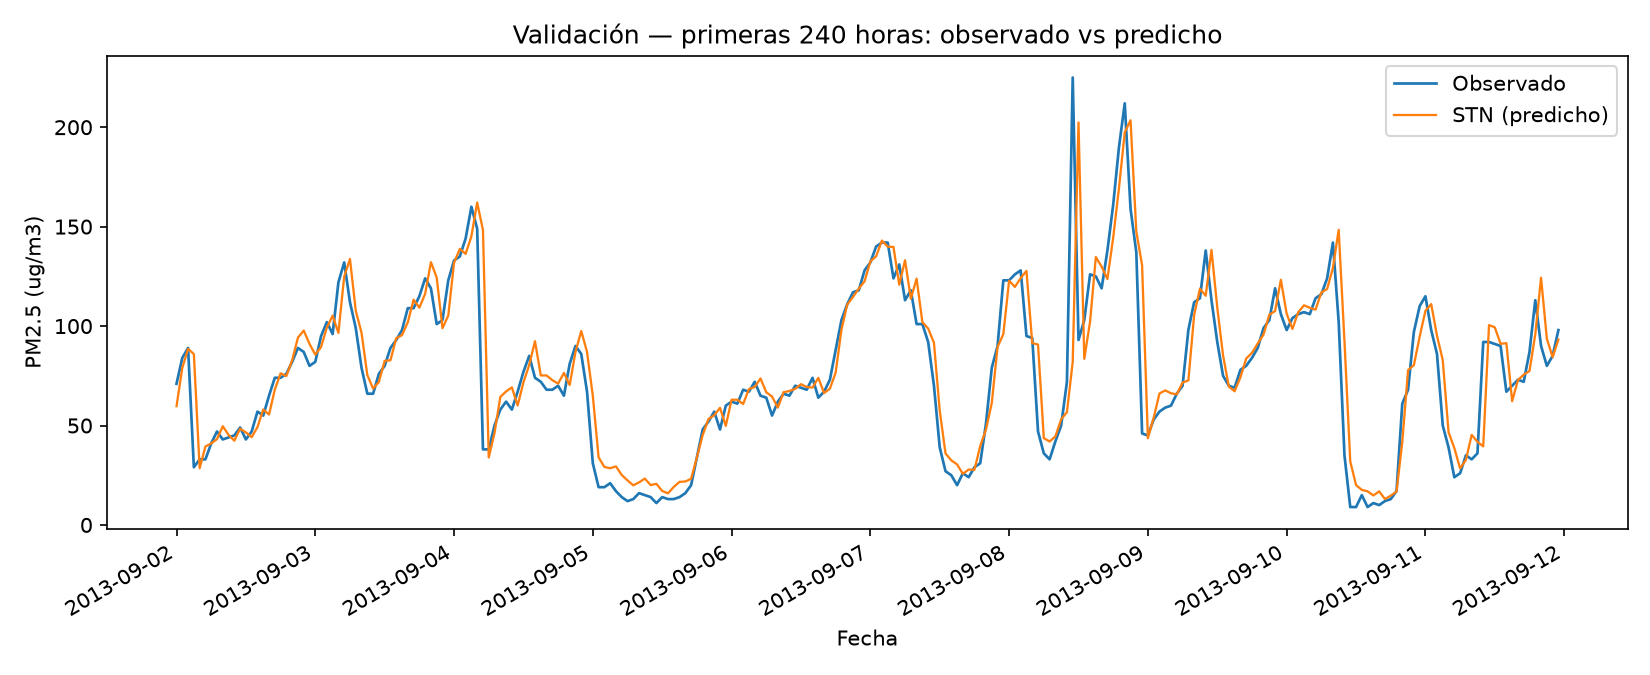

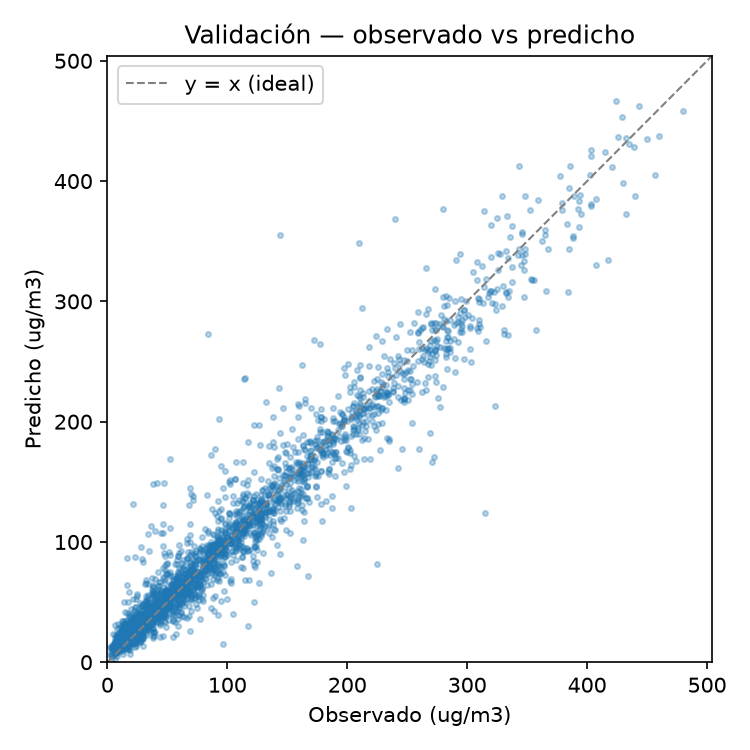

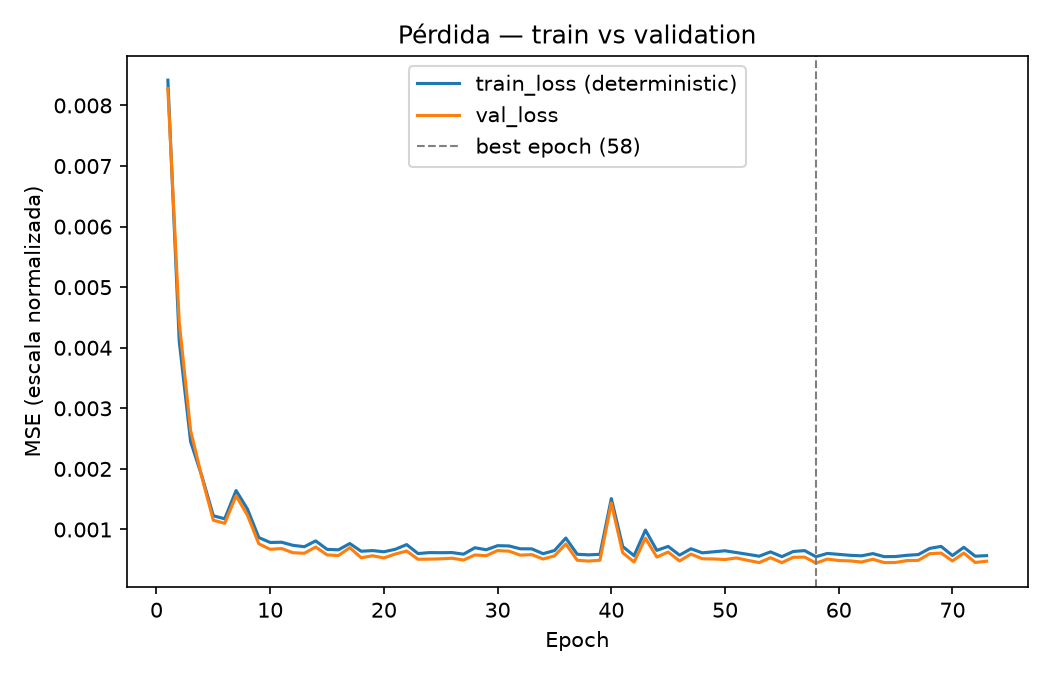

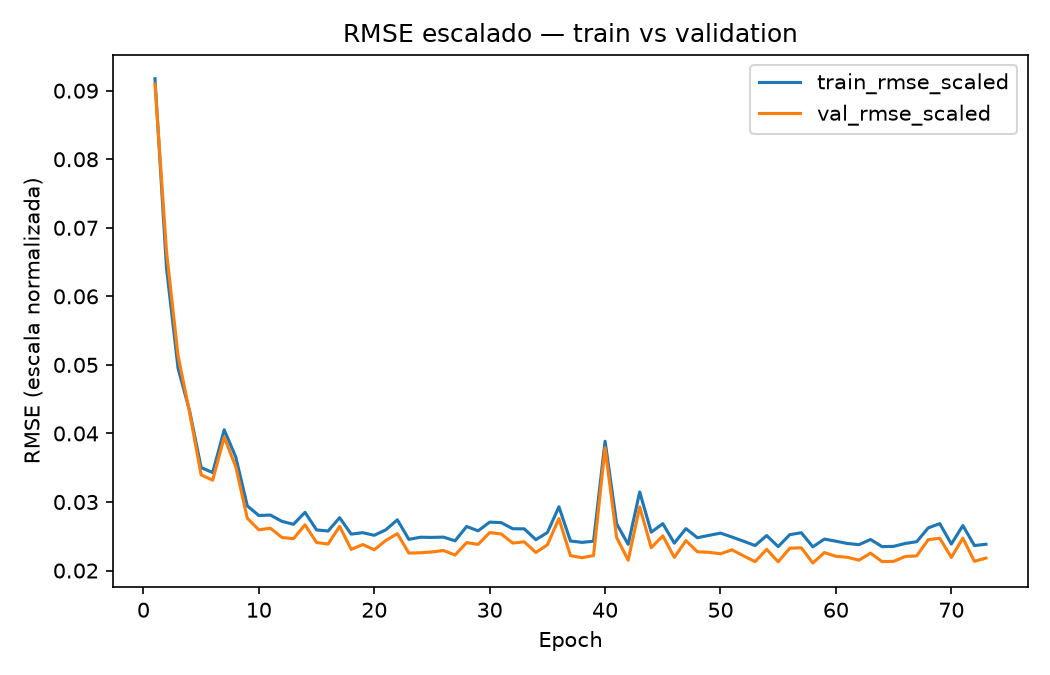

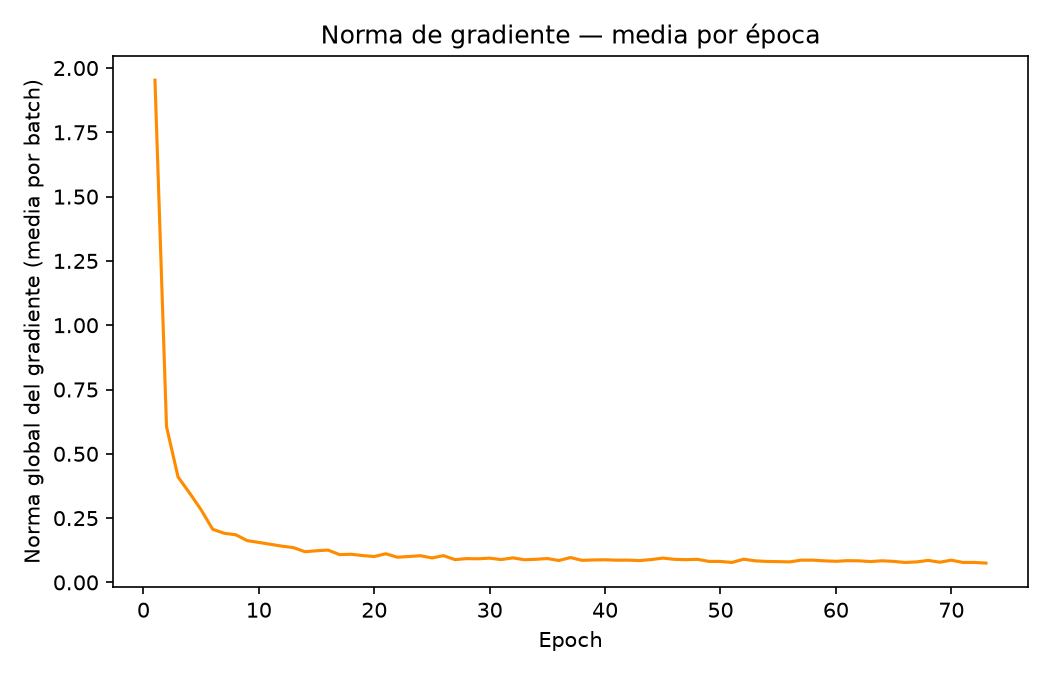

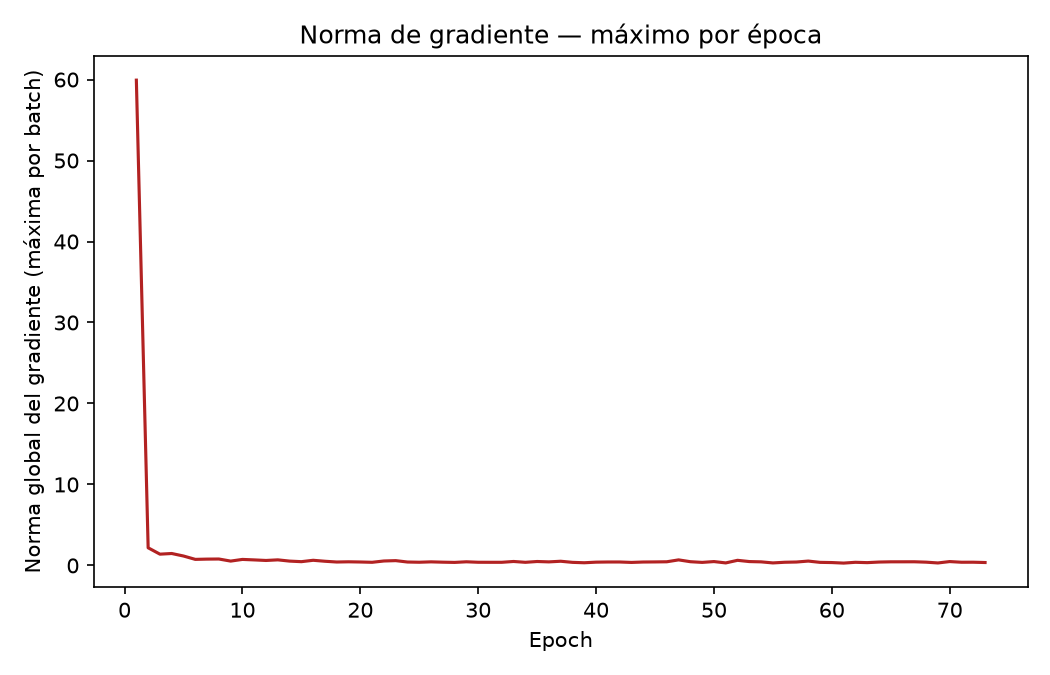

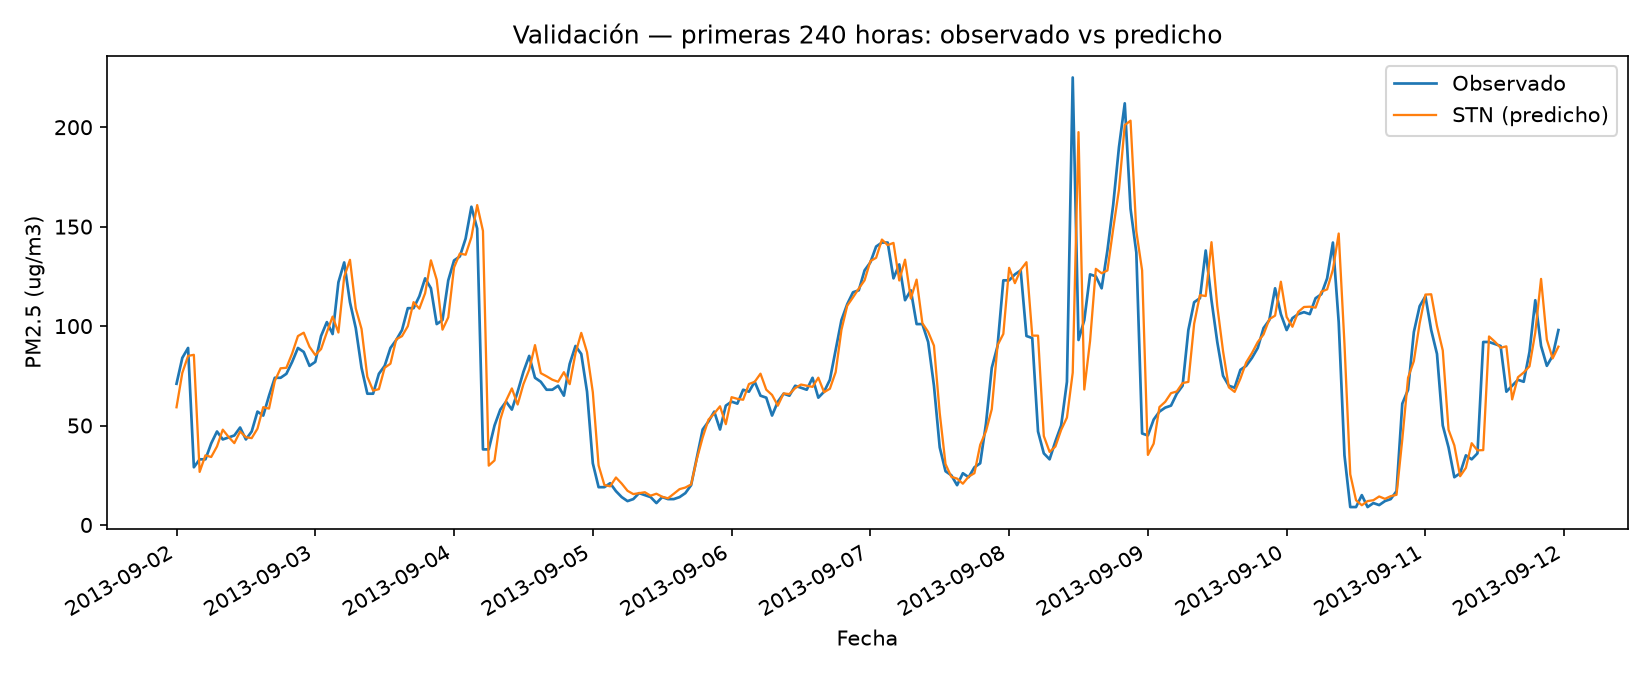

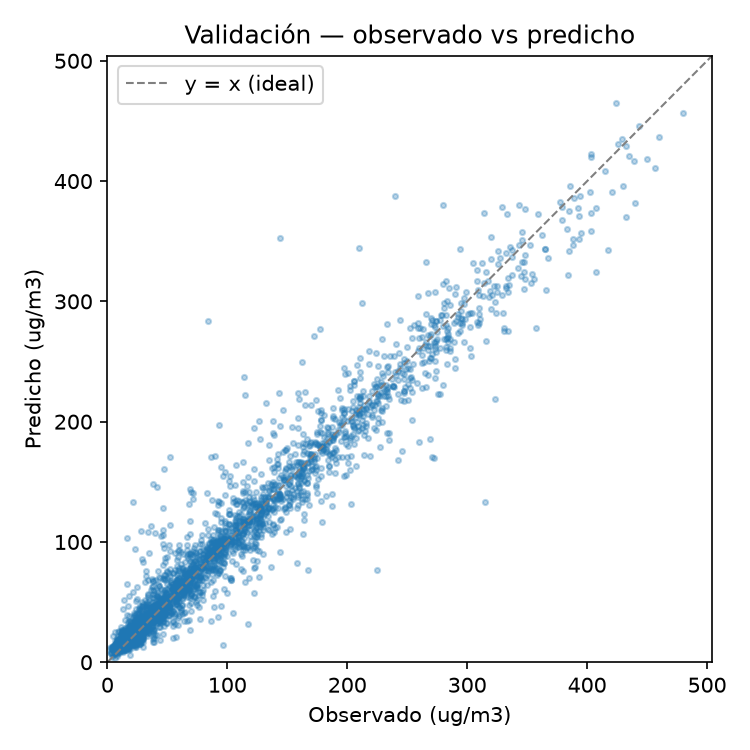

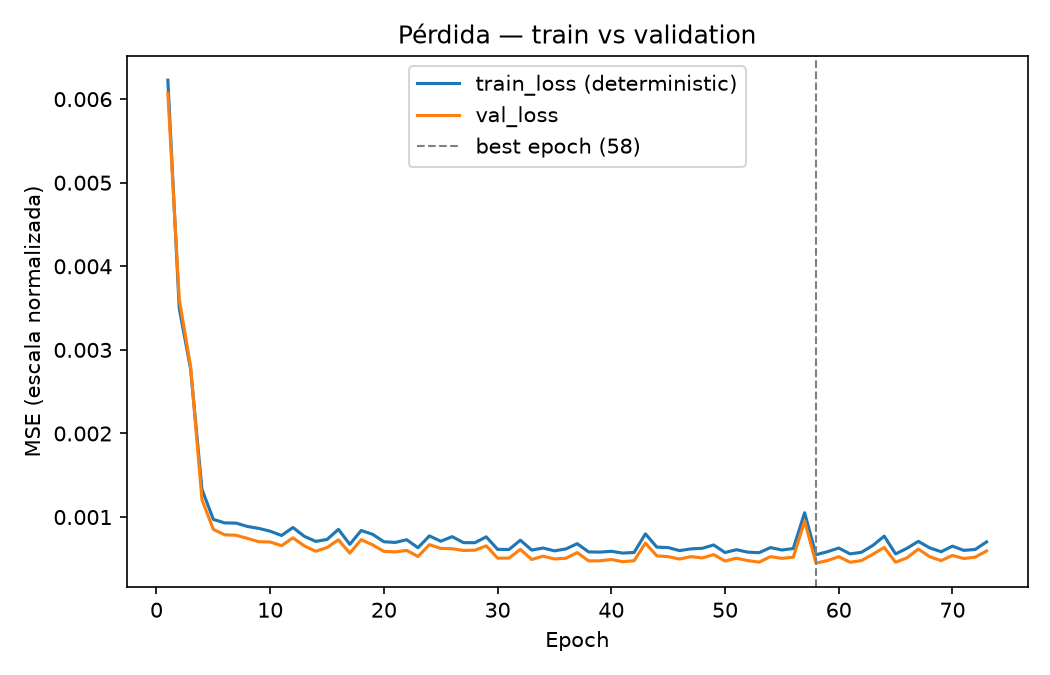

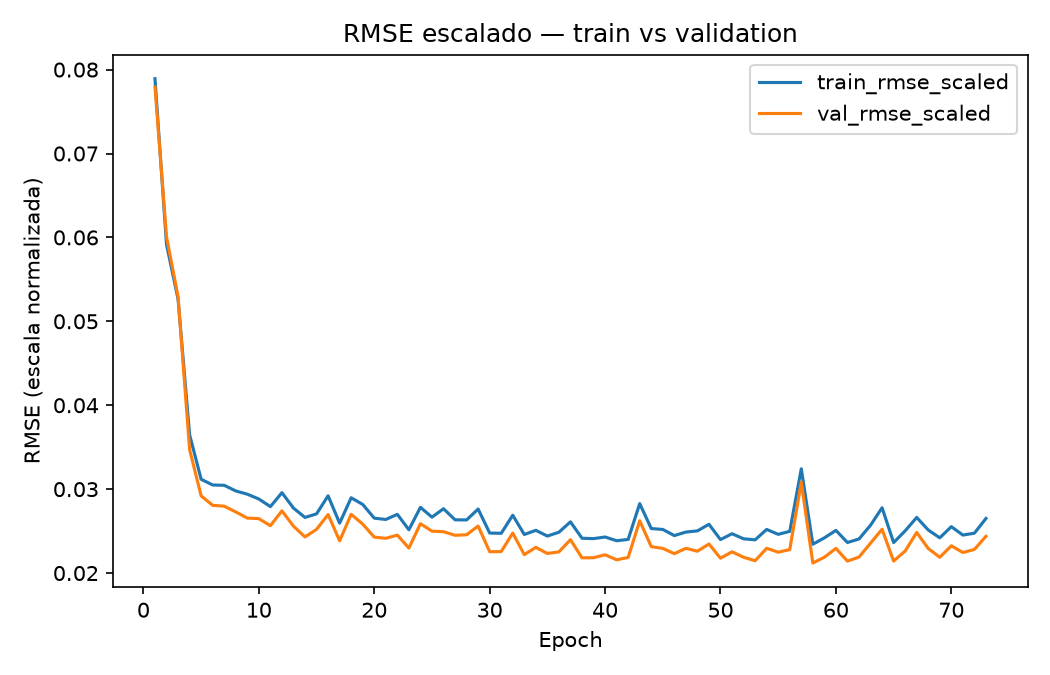

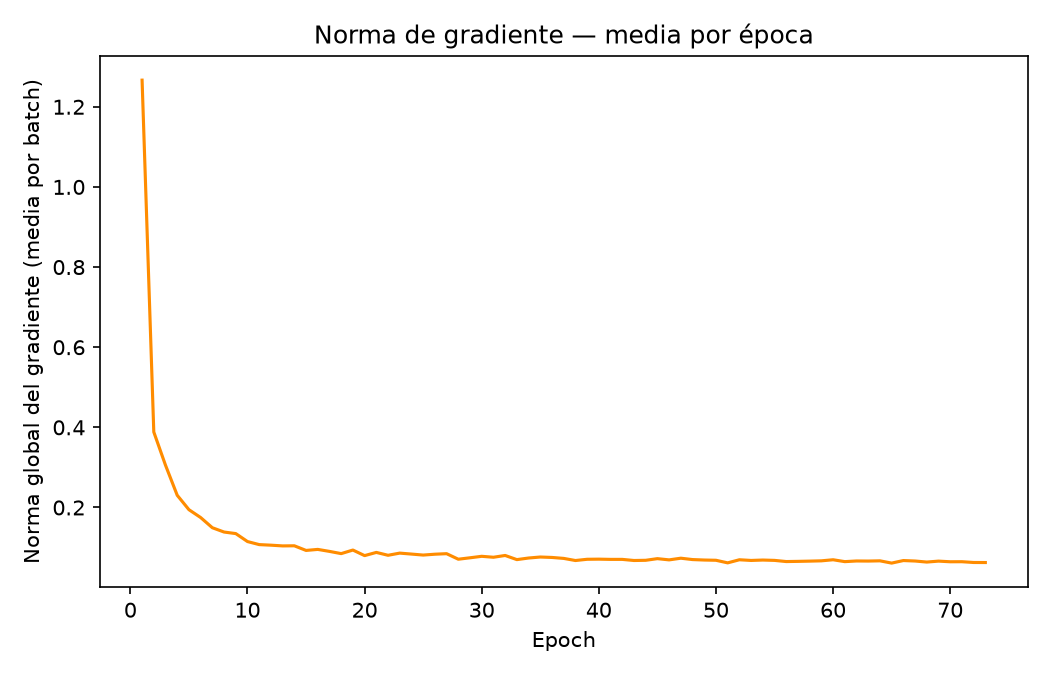

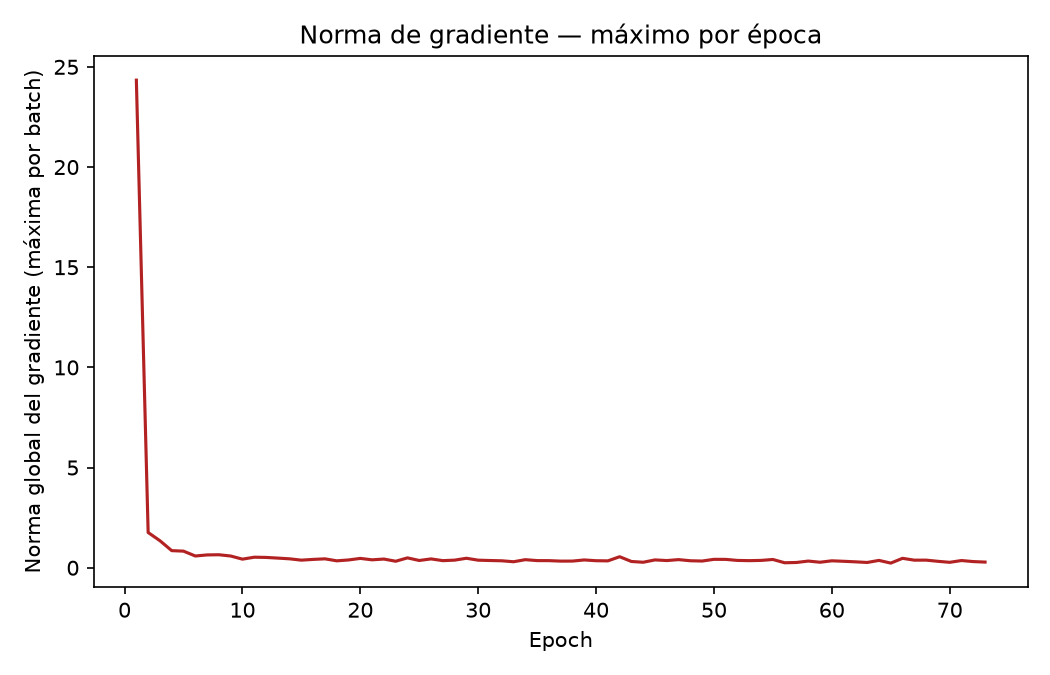

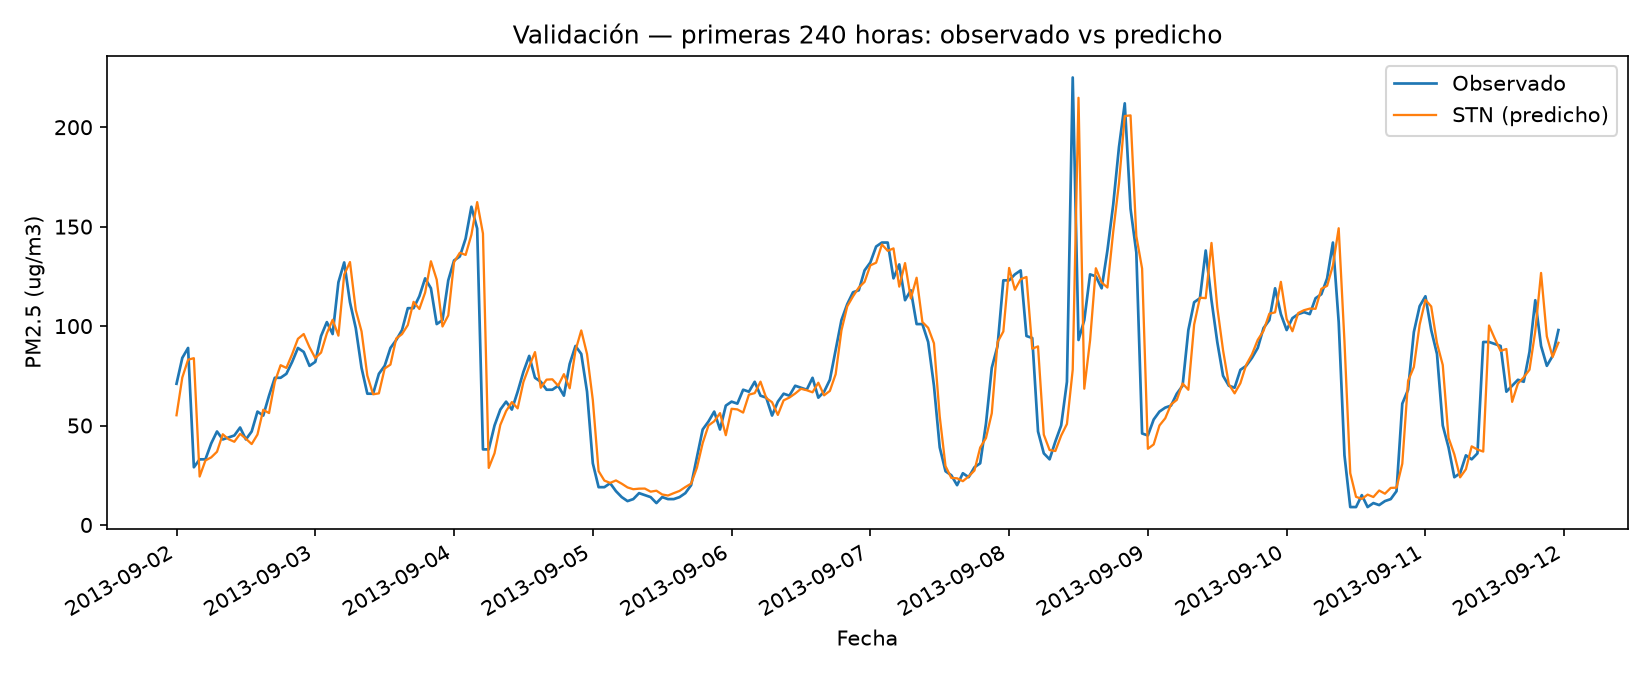

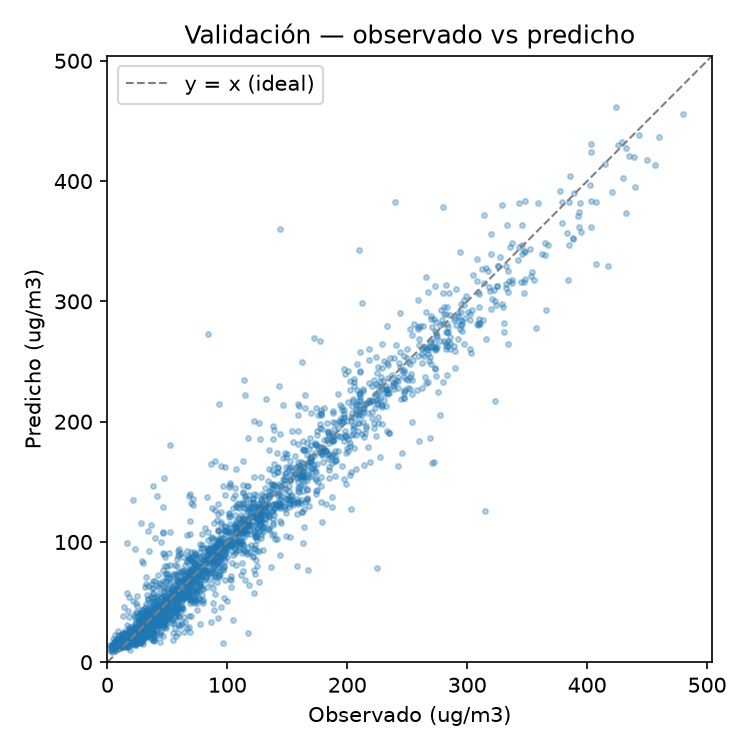

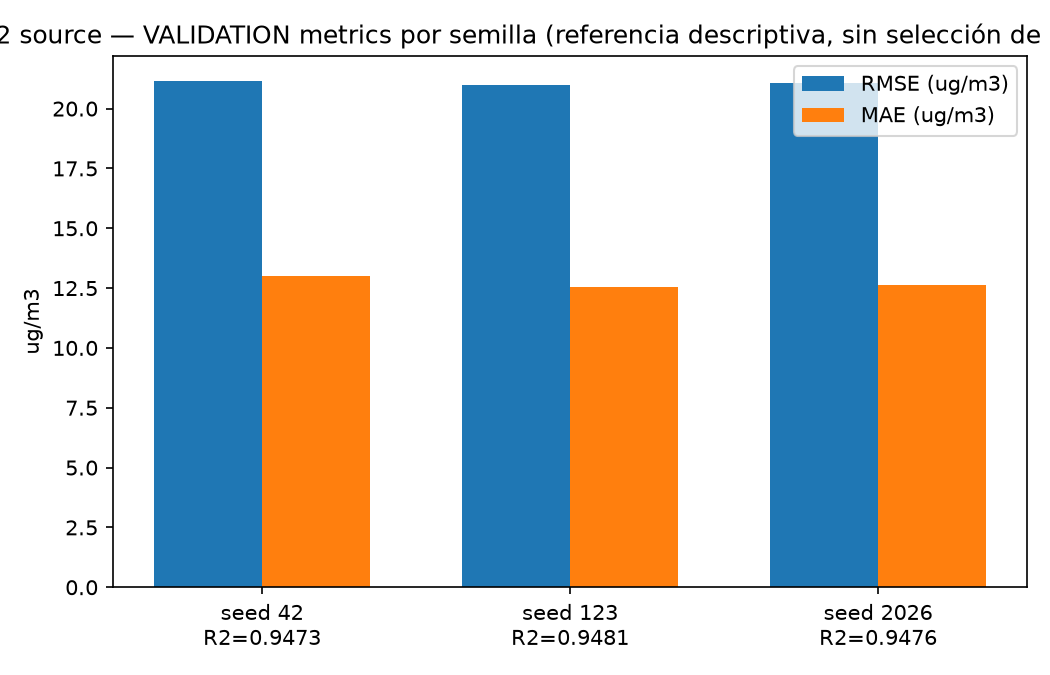

In [22]:
for seed in [42, 123, 2026]:
    run_name = f"R2_source_seed{seed}"
    for fname in [
        "loss_train_vs_validation.png", "rmse_scaled_train_vs_validation.png",
        "gradient_norm_mean.png", "gradient_norm_max.png",
        "validation_predictions_vs_real.png", "validation_scatter_real_vs_pred.png",
    ]:
        fpath = OUTPUTS_DIR / "figures" / run_name / fname
        if fpath.exists():
            display(Image(filename=str(fpath)))

agg_fig = OUTPUTS_DIR / "figures" / "R2_source_comparison" / "R2_validation_metrics_across_seeds.png"
if agg_fig.exists():
    display(Image(filename=str(agg_fig)))

#### Conclusión de R2

Las tres semillas llegan a resultados de validación muy parecidos entre sí (RMSE 21.060 ± 0.085 µg/m³, R² 0.9477 ± 0.0004 — una dispersión incluso menor que en R1), lo que confirma que la arquitectura también es estable con la entrada reducida a tres variables. Los tres checkpoints resultantes se conservan sin elegir uno como definitivo: se verificó, cargando cada uno desde disco, que sus pesos son compatibles en forma con un modelo diseñado para Fontibón, y la cabeza de salida nunca se transfiere — siempre se reinicializa para el dominio destino. R2 queda así completo y disponible como fuente para la transferencia.

## 6. Traslado a Fontibón

El pipeline de datos para Fontibón reutiliza, sin cambios, la lógica validada en la Primera Entrega. Lo nuevo es que ahora se construye únicamente con las tres variables compartidas con Beijing, en el mismo orden, usando un escalador propio de Fontibón — nunca el de Beijing, porque los niveles de PM2.5 de las dos ciudades son muy distintos (sección 3).

In [23]:
fontibon_audit = json.loads((OUTPUTS_DIR / "metrics" / "fontibon_stn_preprocessing_audit.json").read_text(encoding="utf-8"))
print("feature_names:", fontibon_audit["feature_names"])
print("n_windows:", fontibon_audit["n_windows"], "(esperado: train=10802, validation=2564, test=2574 si se construye)")
print("encoder_input_shape:", fontibon_audit["encoder_input_shape"], "| decoder_input_shape:", fontibon_audit["decoder_input_shape"])
print("escalador propio de Fontibon (no el de Beijing):", fontibon_audit["scaler_is_fontibons_own_not_beijings"])
print("Fontibon test construido en esta auditoria:", fontibon_audit["fontibon_test_used"], "(nunca evaluado en ningun caso)")

feature_names: ['pm25', 'temp', 'dew']
n_windows: {'train': 10802, 'validation': 2564, 'test': None} (esperado: train=10802, validation=2564, test=2574 si se construye)
encoder_input_shape: [24, 3] | decoder_input_shape: [13, 1]
escalador propio de Fontibon (no el de Beijing): True
Fontibon test construido en esta auditoria: False (nunca evaluado en ningun caso)


## 7. Transferencia de aprendizaje

Se evaluaron tres configuraciones de entrenamiento sobre Fontibón, incluyendo una sin transferencia, comparadas siempre sobre la partición de validación (2.564 ventanas) y nunca sobre el conjunto de prueba, que permanece reservado para la entrega final:

- **A — desde cero**: no usa ningún peso preentrenado; toda la red se entrena con inicialización aleatoria. Sirve como control: ¿qué tan bien le va al modelo sin ninguna ayuda de Beijing?
- **B — extractor de características**: carga el encoder y el decoder preentrenados en R2 y los congela por completo; solo se entrena una cabeza de salida nueva.
- **C — ajuste parcial**: carga los mismos pesos de R2, pero congela solo el encoder; el decoder y la cabeza sí se entrenan.

Una cuarta configuración, D —ajuste completo con tasas de aprendizaje distintas para el encoder y el resto de la red—, se implementó y se verificó con un piloto corto de integración, pero no se entrenó por completo con ninguna semilla; se documenta su diseño y el resultado del piloto, sin presentarlo como un resultado comparable a los demás.

| Config | Encoder | Decoder | Cabeza | LR encoder | LR decoder/cabeza | Por qué |
|---|---|---|---|---|---|---|
| A | entrenable | entrenable | entrenable (nueva) | 1e-4 | 1e-4 | Control sin transferencia: qué logra la arquitectura sin ayuda de Beijing. |
| B | congelado | congelado | entrenable (nueva) | — | 1e-4 | Conserva al máximo lo aprendido en Beijing; solo adapta la salida al nuevo dominio. |
| C | congelado | entrenable | entrenable | — | 1e-4 | Deja que la parte generativa (decoder) se adapte a Fontibón, conservando solo el encoder. |
| D* | entrenable | entrenable | entrenable | 1e-5 | 1e-4 | Ajuste completo; el encoder se mueve más despacio por partir de una representación ya útil. |

*Config D solo cuenta con un piloto de integración (2 épocas); no tiene entrenamiento completo con ninguna semilla.

En todos los casos la cabeza de salida es nueva y se entrena desde cero: nunca se transfiere, porque los niveles de PM2.5 de Beijing y Fontibón son demasiado distintos como para que una cabeza entrenada en Beijing tenga sentido en Fontibón.

### 7.1 Config A — desde cero (3 semillas completas)

In [24]:
def show_config_results(cfg):
    pp = OUTPUTS_DIR / "metrics" / f"transfer_pilot_{cfg}_seed42_summary.json"
    if pp.exists():
        pilot = json.loads(pp.read_text(encoding="utf-8"))
        print(f"Pilot (2 epocas, 512/128 ventanas, NO resultado final): val RMSE={pilot['validation_metrics_ug_m3']['RMSE']:.3f}")
    rows = []
    for seed in [42, 123, 2026]:
        p = OUTPUTS_DIR / "metrics" / f"transfer_{cfg}_seed{seed}_summary.json"
        if not p.exists():
            continue
        s = json.loads(p.read_text(encoding="utf-8"))
        if s.get("status", "").startswith("INCOMPLETE"):
            rows.append({"seed": seed, "status": "INCOMPLETO (detenido por plazo, no es resultado final)"})
        else:
            vm = s["validation_metrics_ug_m3"]
            rows.append({"seed": seed, "best_epoch": s["best_epoch"], "stopping_epoch": s["stopping_epoch"],
                         "val_RMSE": round(vm["RMSE"], 3), "val_MAE": round(vm["MAE"], 3), "val_R2": round(vm["R2"], 4),
                         "bias": round(s["validation_residual_diagnostics_ug_m3"]["bias_mean"], 3)})
    if rows:
        display(pd.DataFrame(rows))
    else:
        print("Entrenamiento completo aun no disponible para esta configuracion.")

show_config_results("A")

Pilot (2 epocas, 512/128 ventanas, NO resultado final): val RMSE=16.993


,seed,best_epoch,stopping_epoch,val_RMSE,val_MAE,val_R2,bias
0,42,102,117,6.384,4.601,0.6068,-0.087
1,123,96,111,6.285,4.554,0.6190,0.115
2,2026,110,125,6.274,4.486,0.6202,-0.064


### 7.2 Config B — extractor de características, encoder y decoder congelados (2 semillas completas, una provisional)

In [25]:
show_config_results("B")

Pilot (2 epocas, 512/128 ventanas, NO resultado final): val RMSE=8.545


,seed,best_epoch,stopping_epoch,val_RMSE,val_MAE,val_R2,bias
0,42,188,200,6.823,4.972,0.5509,0.030
1,123,111,126,6.845,4.989,0.5480,0.034


In [26]:
prov_path = OUTPUTS_DIR / "metrics" / "transfer_B_seed2026_PROVISIONAL_summary.json"
if prov_path.exists():
    prov = json.loads(prov_path.read_text(encoding="utf-8"))
    print("B seed2026 -- PROVISIONAL (entrenamiento interrumpido por reinicio del equipo en la epoca 83;")
    print("evaluado por inferencia pura sobre el checkpoint de la mejor epoca, la 74 -- no es resultado final):")
    print(prov["validation_metrics_ug_m3"])

B seed2026 -- PROVISIONAL (entrenamiento interrumpido por reinicio del equipo en la epoca 83;
evaluado por inferencia pura sobre el checkpoint de la mejor epoca, la 74 -- no es resultado final):
{'RMSE': 6.945013171030118, 'MAE': 5.0853886458133575, 'R2': 0.534669108106769}


### 7.3 Config C — ajuste parcial, solo el encoder congelado (3 semillas completas)

In [27]:
show_config_results("C")

Pilot (2 epocas, 512/128 ventanas, NO resultado final): val RMSE=6.160


,seed,best_epoch,stopping_epoch,val_RMSE,val_MAE,val_R2,bias
0,42,59,74,6.621,4.812,0.5771,-0.074
1,123,46,61,6.591,4.820,0.5809,0.121
2,2026,53,68,6.670,4.857,0.5707,-0.001


### 7.4 Config D — ajuste completo con tasas diferenciadas (solo piloto de integración)

In [28]:
show_config_results("D")

Pilot (2 epocas, 512/128 ventanas, NO resultado final): val RMSE=6.149
Entrenamiento completo aun no disponible para esta configuracion.


## 8. Dinámica del entrenamiento

### 8.1 Curvas de pérdida y RMSE

En las tres configuraciones completas, train y validation se mantienen muy cerca durante todo el entrenamiento: en la época de mejor validación, la diferencia entre ambas pérdidas es del orden de 10⁻⁴-10⁻⁵ (menos del 7% de la pérdida misma), y en 6 de las 8 corridas val_loss queda incluso por debajo de train_loss. En el rango de épocas entrenado, esto no muestra señales de sobreajuste; no se puede descartar que aparecería si se siguiera entrenando mucho más allá del punto de parada, algo que este experimento no exploró. El detalle numérico por semilla está en `docs/ANALISIS_SOBREAJUSTE.md`.

A seed 42


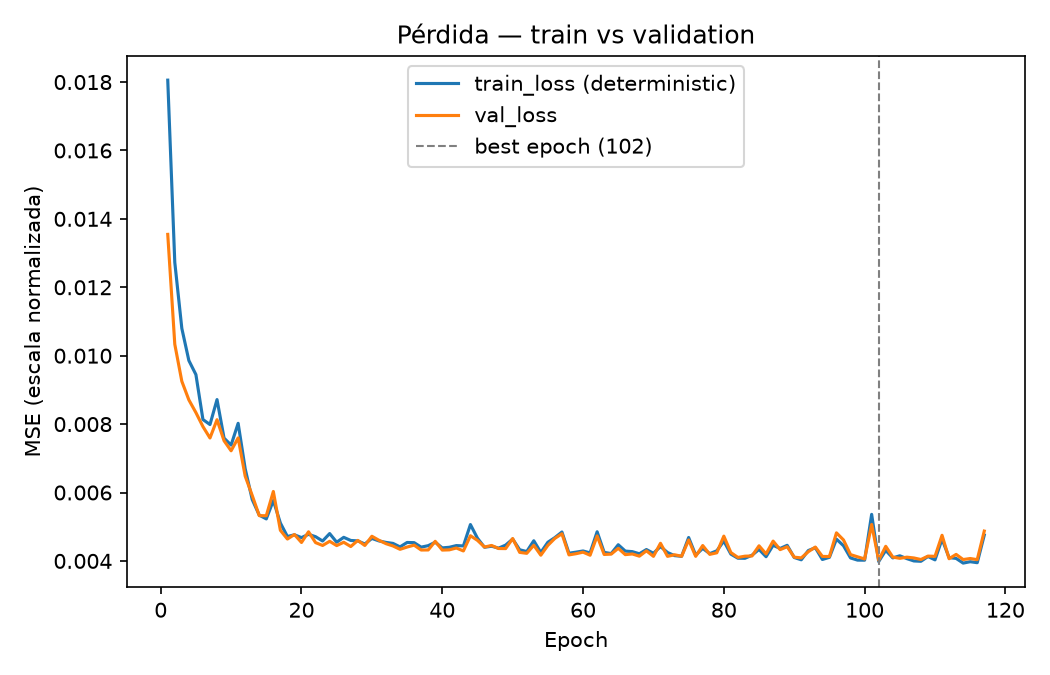

A seed 123


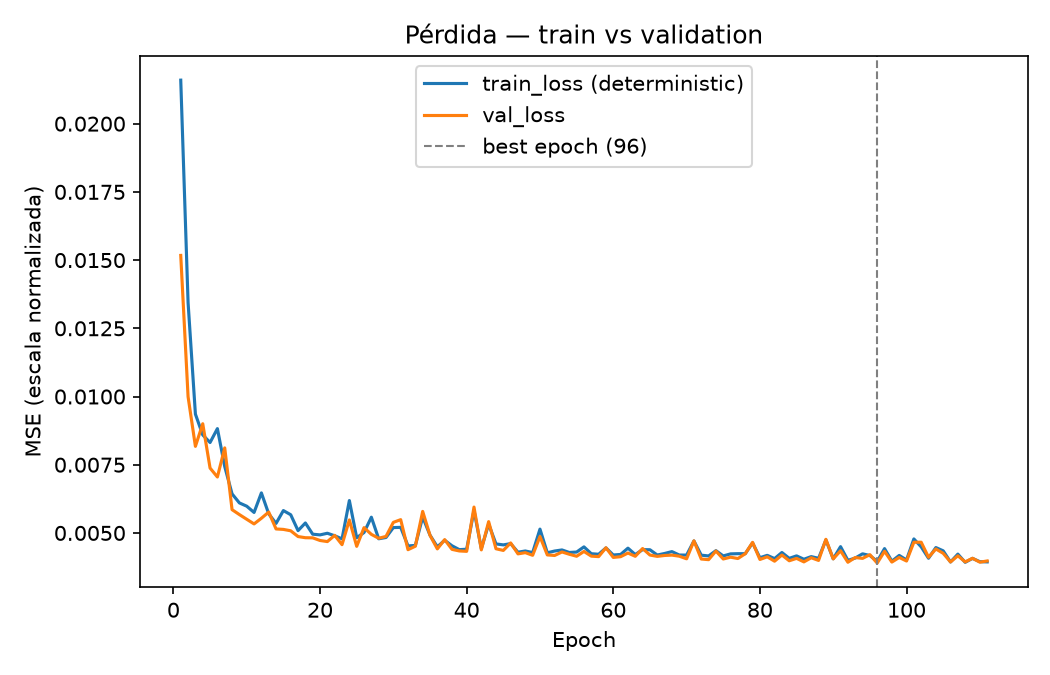

A seed 2026


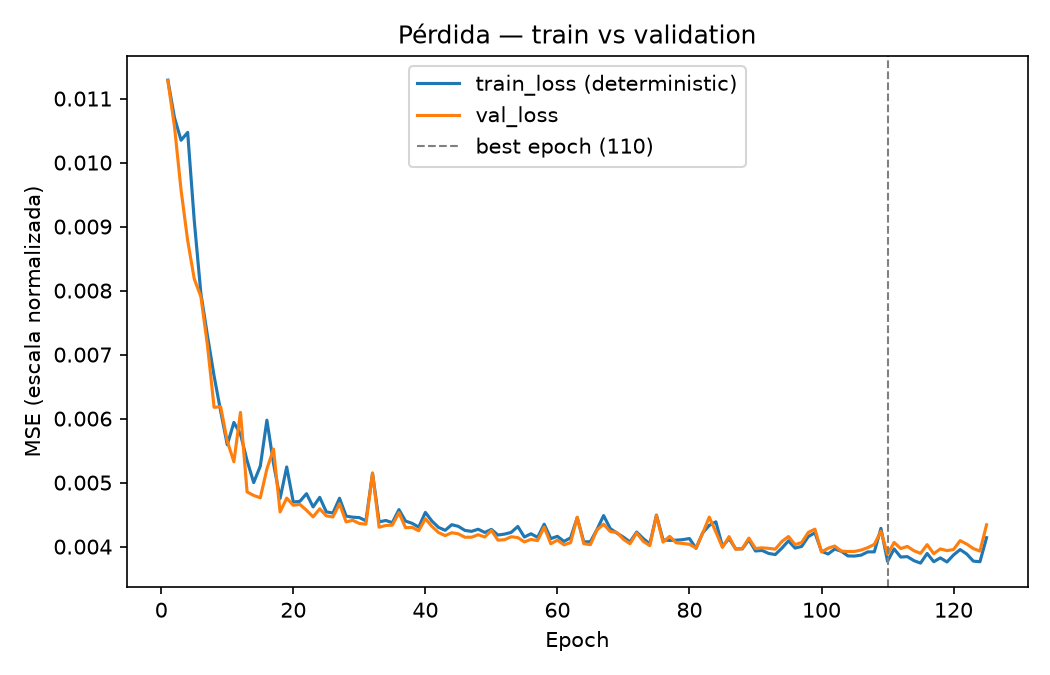

B seed 42


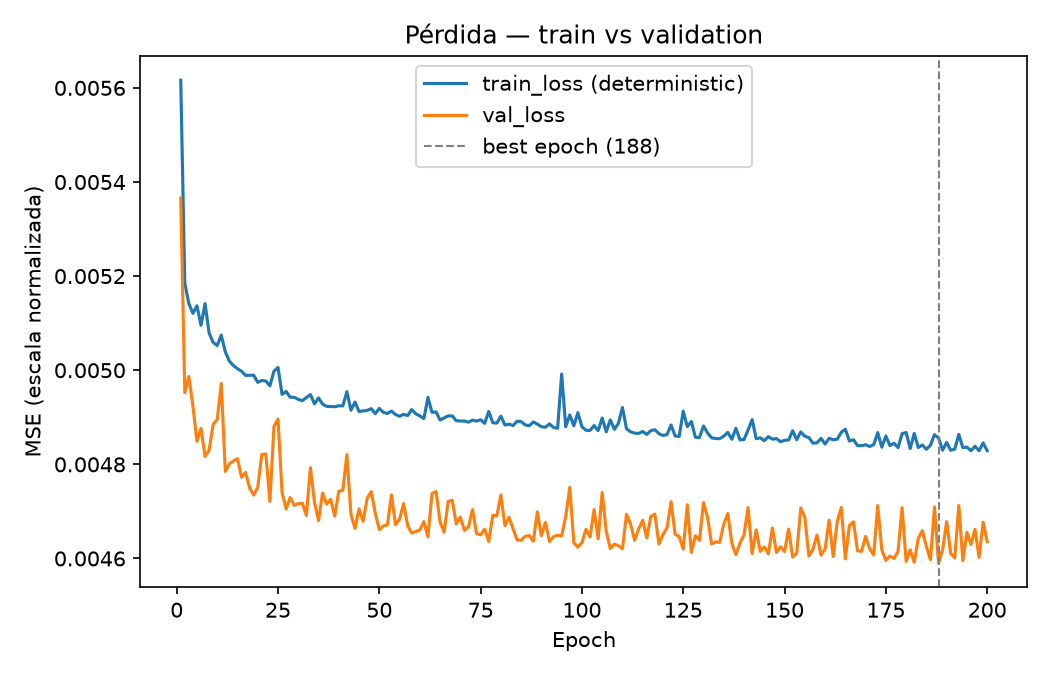

B seed 123


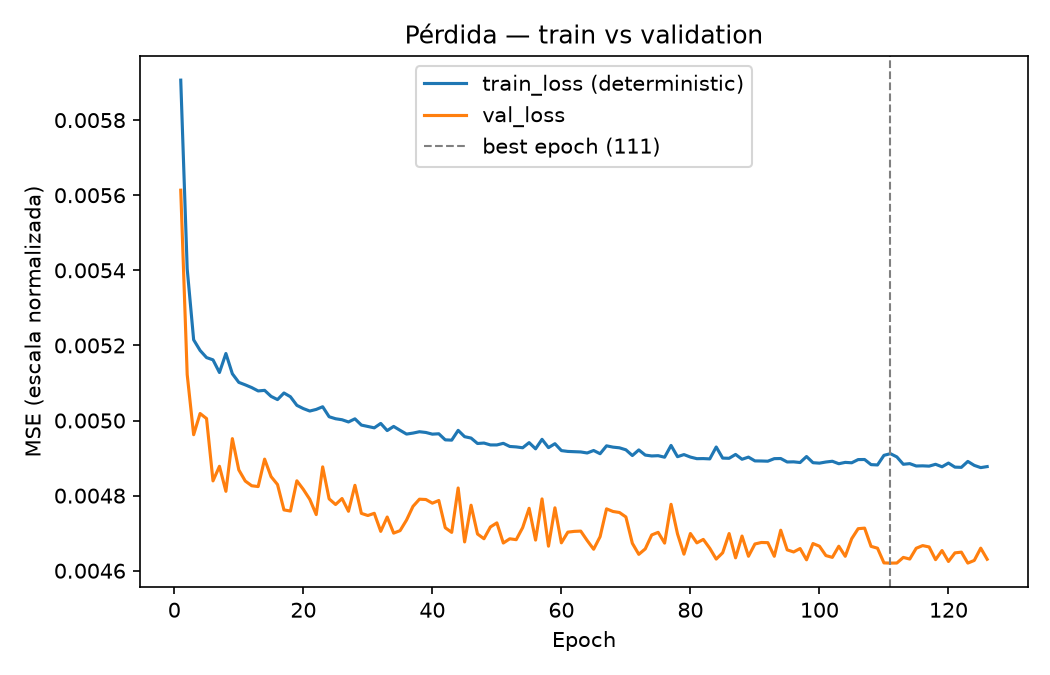

C seed 42


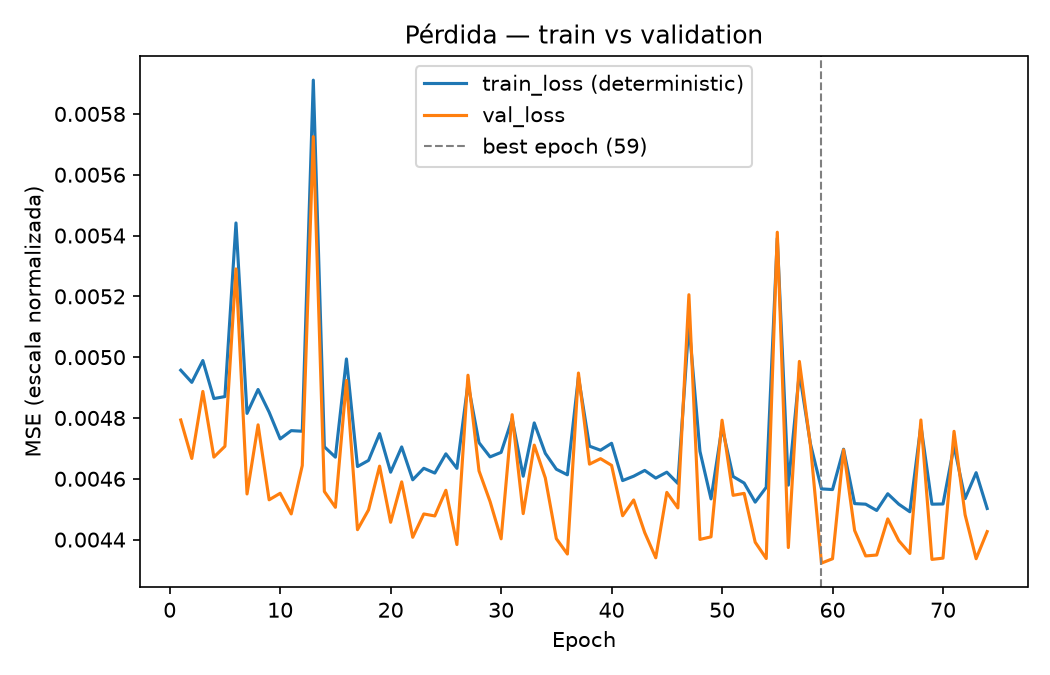

C seed 123


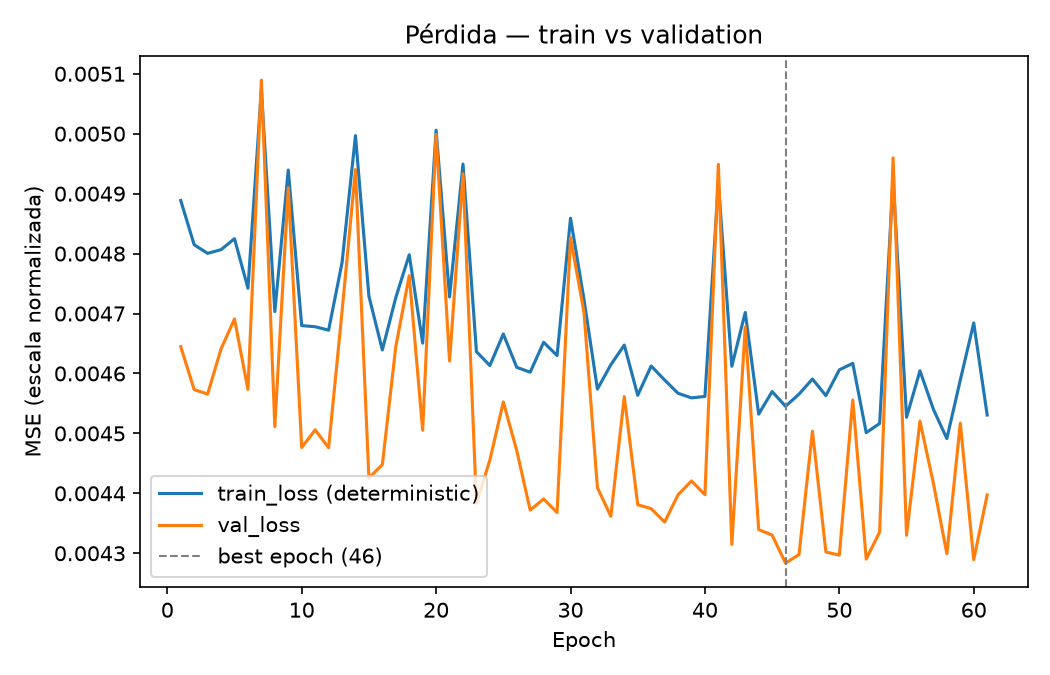

C seed 2026


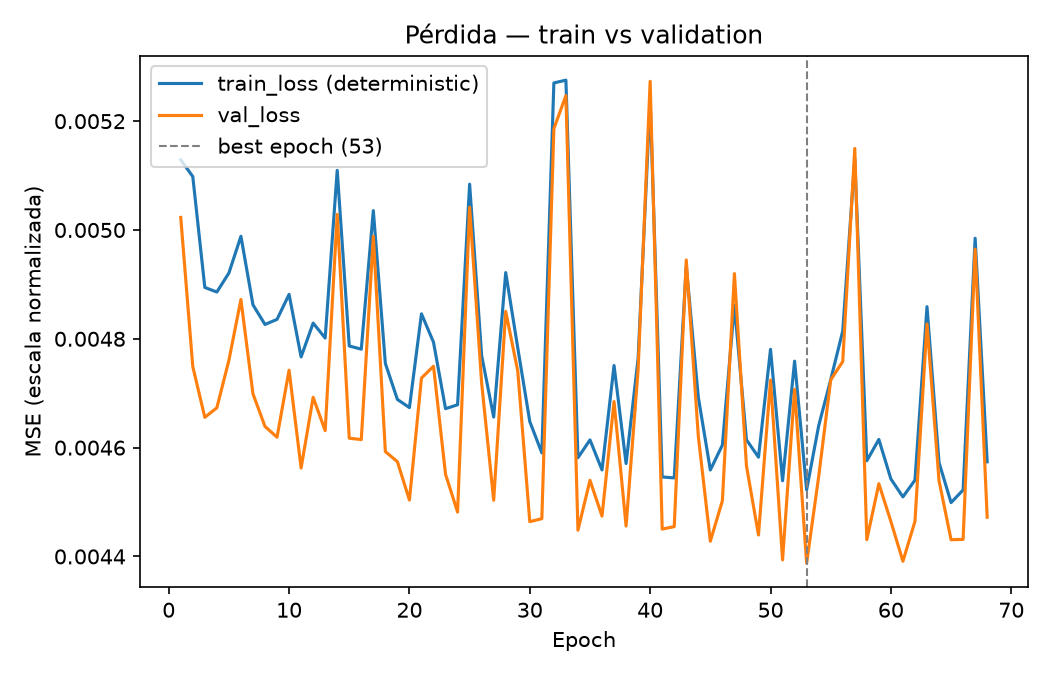

In [29]:
for cfg in ["A", "B", "C", "D"]:
    for seed in [42, 123, 2026]:
        fpath = OUTPUTS_DIR / "figures" / f"transfer_{cfg}_seed{seed}" / "loss_train_vs_validation.png"
        if fpath.exists():
            print(f"{cfg} seed {seed}")
            display(Image(filename=str(fpath)))

### 8.2 Norma del gradiente

El patrón es consistente con lo esperado: Config A arranca con gradientes 10-20 veces mayores que B y C (máximos de hasta 71, frente a menos de 3), porque su encoder se inicializa al azar y parte lejos de cualquier solución razonable. B y C, al partir de los pesos preentrenados en Beijing, arrancan con activaciones ya cercanas a una solución razonable y el gradiente se mantiene bajo desde el principio. En los tres casos el gradiente decrece hacia el final del entrenamiento, sin señales de explosión ni divergencia.

Esta métrica es útil para diagnosticar estabilidad numérica del entrenamiento y para comparar cuánto necesita ajustarse cada configuración desde su punto de partida. No debe leerse como prueba de que el modelo convergió a un óptimo global —podría tratarse de un óptimo local o de una región plana de la superficie de pérdida— ni como garantía de mejor capacidad de generalización; ambas cosas requerirían evidencia adicional que esta métrica, por sí sola, no provee.

A seed 42


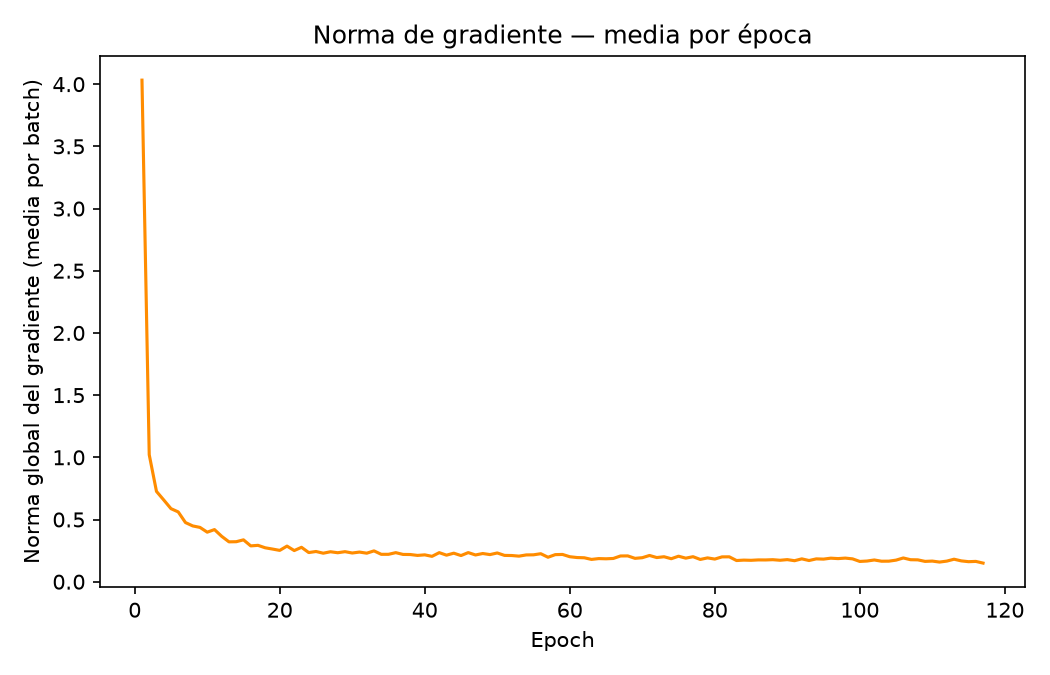

A seed 123


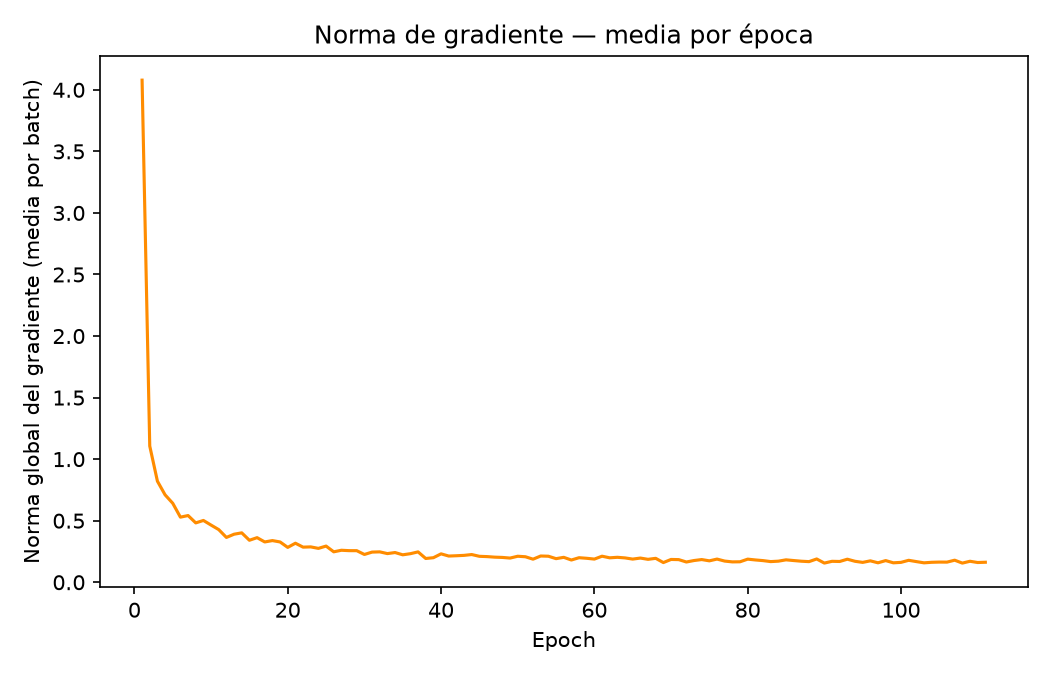

A seed 2026


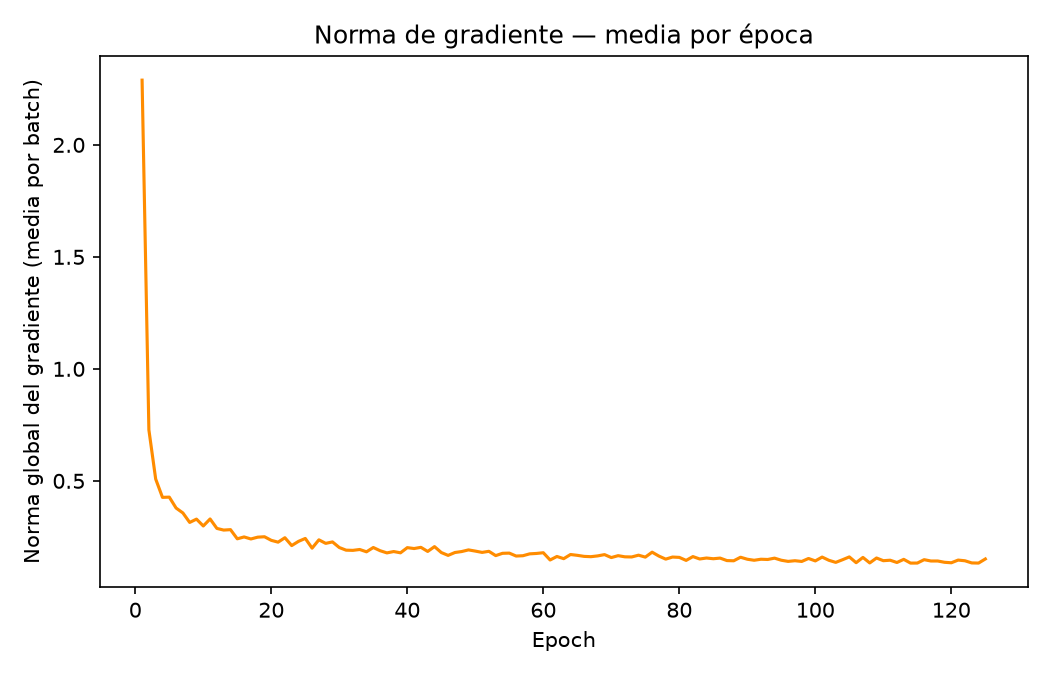

B seed 42


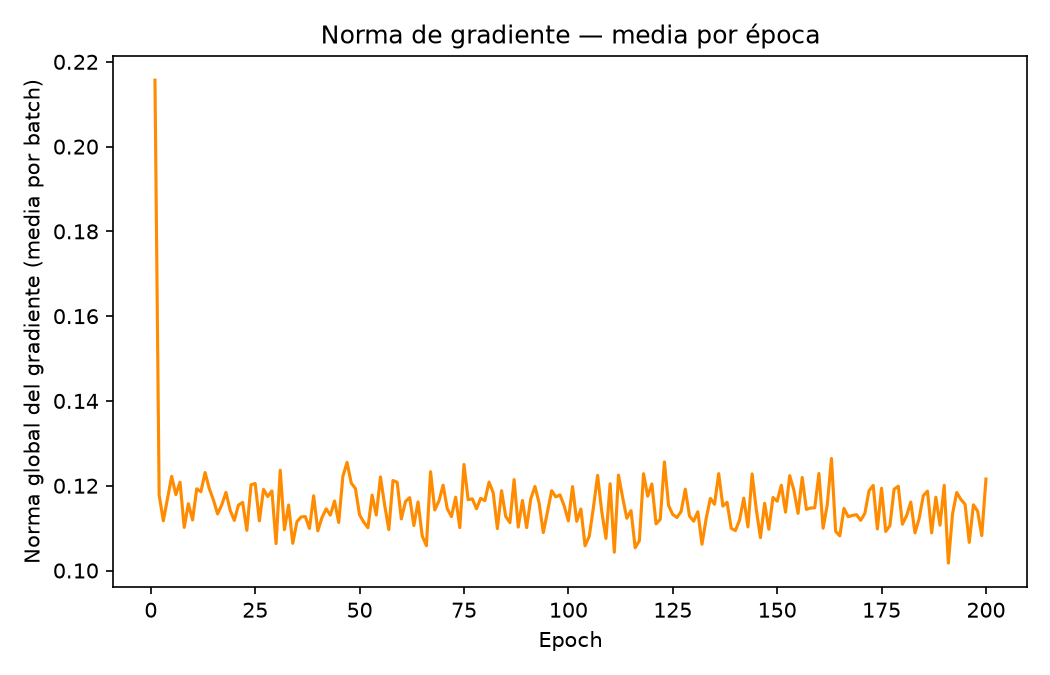

B seed 123


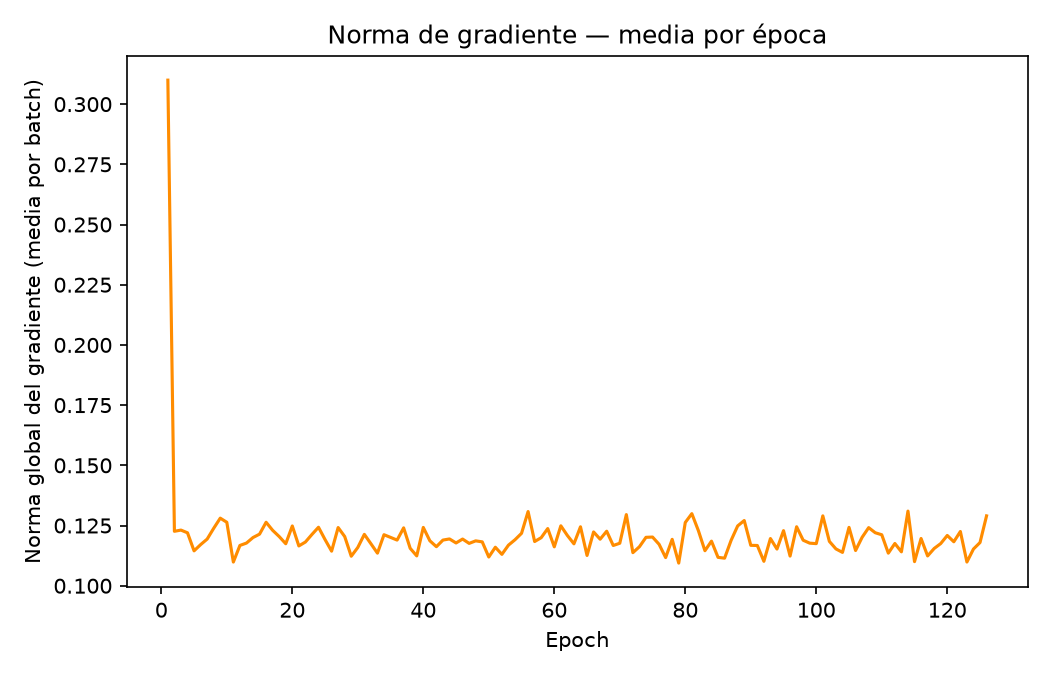

C seed 42


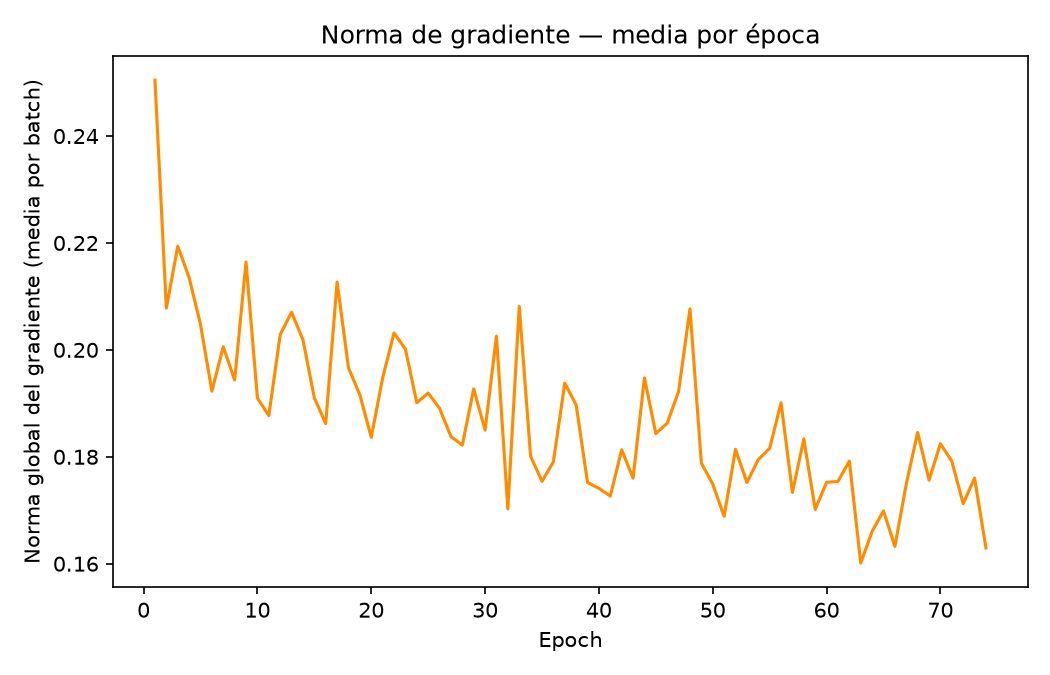

C seed 123


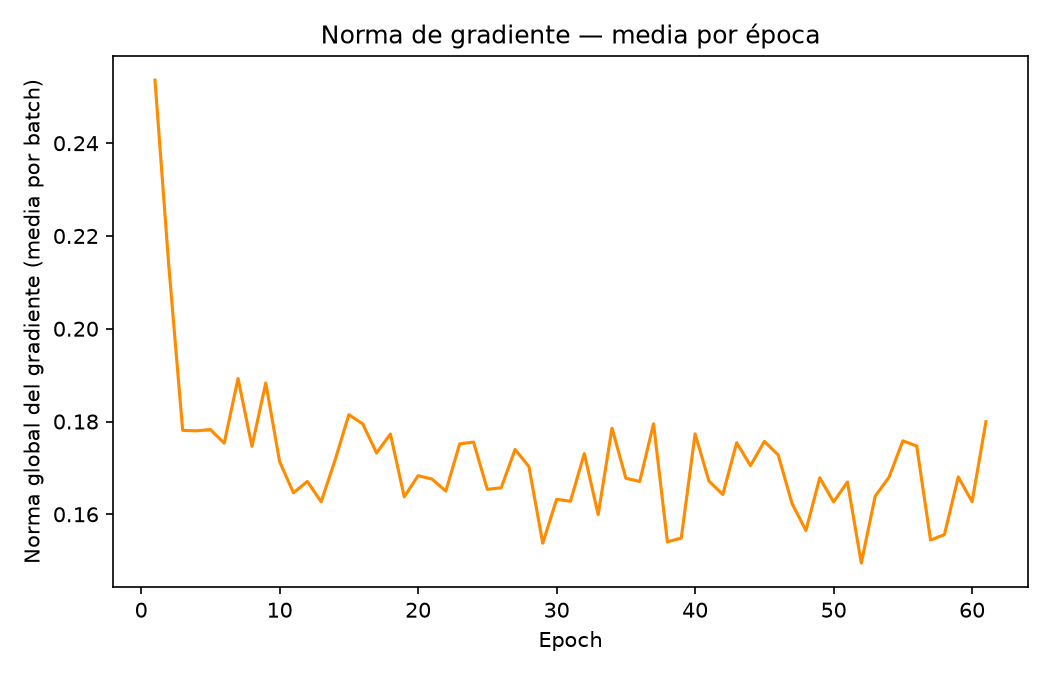

C seed 2026


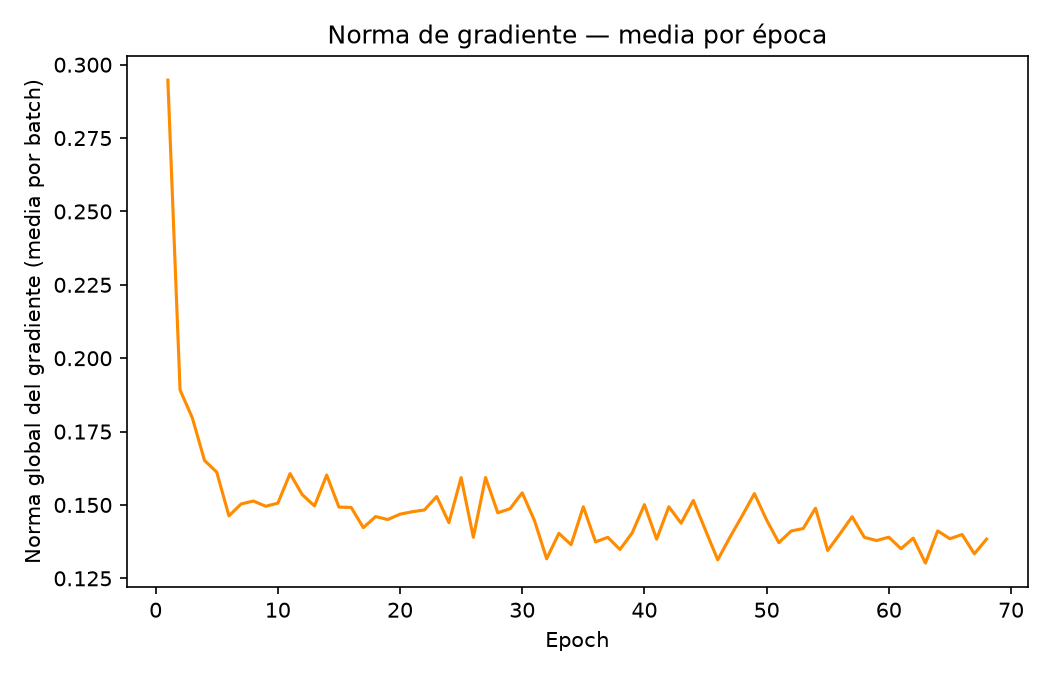

In [30]:
for cfg in ["A", "B", "C", "D"]:
    for seed in [42, 123, 2026]:
        fpath = OUTPUTS_DIR / "figures" / f"transfer_{cfg}_seed{seed}" / "gradient_norm_mean.png"
        if fpath.exists():
            print(f"{cfg} seed {seed}")
            display(Image(filename=str(fpath)))

### 8.3 Variabilidad entre semillas

Config C es la más rápida y la más consistente entre semillas (mejor época entre 46 y 59, en 1.2-1.9 horas). Config A varía algo más en número de épocas (96-110) pero llega a un RMSE final similar en las tres semillas. Config B muestra la mayor variación en su dinámica de entrenamiento: una semilla necesitó 111 épocas y otra llegó al tope de 200 sin agotar la paciencia configurada (12 épocas sin mejora, no 15), lo que sugiere una convergencia más lenta e inconsistente pese a partir también de pesos preentrenados — posiblemente porque congelar encoder y decoder deja muy poca capacidad de ajuste en la cabeza de salida. B es también la configuración más costosa computacionalmente (hasta 4.4 horas por semilla, frente a 1.2-1.9 de C).

In [31]:
import numpy as np

for cfg in ["A", "B", "C", "D"]:
    rmses = []
    for seed in [42, 123, 2026]:
        p = OUTPUTS_DIR / "metrics" / f"transfer_{cfg}_seed{seed}_summary.json"
        if p.exists():
            s = json.loads(p.read_text(encoding="utf-8"))
            if not s.get("status", "").startswith("INCOMPLETE"):
                rmses.append(s["validation_metrics_ug_m3"]["RMSE"])
    arr = np.array(rmses)
    if len(arr) > 1:
        print(f"{cfg}: val RMSE = {arr.mean():.3f} +/- {arr.std(ddof=1):.3f} ug/m3 (n={len(arr)} semillas)")
    elif len(arr) == 1:
        print(f"{cfg}: val RMSE = {arr[0]:.3f} ug/m3 (solo 1 semilla completa hasta el momento)")
    else:
        print(f"{cfg}: sin entrenamientos completos todavia")

A: val RMSE = 6.314 +/- 0.061 ug/m3 (n=3 semillas)
B: val RMSE = 6.834 +/- 0.016 ug/m3 (n=2 semillas)
C: val RMSE = 6.627 +/- 0.040 ug/m3 (n=3 semillas)
D: sin entrenamientos completos todavia


## 9. Comparación contra Ridge

La línea base de la Primera Entrega fue un modelo Ridge, con un RMSE de validación de 6.545 µg/m³ sobre el mismo split de Fontibón. Su resultado de prueba (7.063) se muestra únicamente como referencia histórica: no se recalcula ni se compara contra la STN en esta entrega, porque el conjunto de prueba sigue reservado.

In [32]:
ridge_val_rmse = 6.545  # Primera Entrega, Fontibon validation
print(f"Ridge (referencia, Primera Entrega): val RMSE = {ridge_val_rmse} ug/m3")
print()
for cfg in ["A", "B", "C", "D"]:
    rmses = []
    for seed in [42, 123, 2026]:
        p = OUTPUTS_DIR / "metrics" / f"transfer_{cfg}_seed{seed}_summary.json"
        if p.exists():
            s = json.loads(p.read_text(encoding="utf-8"))
            if not s.get("status", "").startswith("INCOMPLETE"):
                rmses.append(s["validation_metrics_ug_m3"]["RMSE"])
    if rmses:
        arr = np.array(rmses)
        tag = f"{arr.mean():.3f} +/- {arr.std(ddof=1):.3f}" if len(arr) > 1 else f"{arr[0]:.3f}"
        print(f"{cfg}: val RMSE = {tag} ug/m3 (n={len(arr)})")
    else:
        print(f"{cfg}: sin entrenamientos completos todavia")

Ridge (referencia, Primera Entrega): val RMSE = 6.545 ug/m3

A: val RMSE = 6.314 +/- 0.061 ug/m3 (n=3)
B: val RMSE = 6.834 +/- 0.016 ug/m3 (n=2)
C: val RMSE = 6.627 +/- 0.040 ug/m3 (n=3)
D: sin entrenamientos completos todavia


## 10. Conclusiones

Con los resultados disponibles —validación de Fontibón, 2.564 ventanas; la prueba permanece reservada— el panorama es el siguiente.

R1 quedó cerrado con un RMSE de prueba de 21.127 ± 0.400 µg/m³ sobre Beijing (el artículo reporta 19.04), y R2 —la versión preentrenada con las tres variables compartidas— resultó igual de estable (21.060 ± 0.085 µg/m³). El análisis de distancia entre dominios mostró que la media de PM2.5 en Beijing es cerca de 5.2 veces la de Fontibón y su desviación estándar cerca de 8.5 veces mayor; al remover esa diferencia de escala, las distribuciones estandarizadas se parecen más entre sí. Esto no demuestra que la dinámica temporal aprendida en Beijing sea transferible —la métrica usada compara forma de distribución, no secuencia temporal—, pero sí motivaba intentar la transferencia como hipótesis razonable.

En la práctica, la transferencia no mostró ventaja frente a entrenar desde cero. Config A, que no usa ningún peso de Beijing, terminó con las tres semillas completas por debajo del RMSE de Ridge (6.384, 6.285 y 6.274 µg/m³; media 6.314 ± 0.061, frente a 6.545 de Ridge). Config C, que congela solo el encoder, quedó un poco por encima (6.627 ± 0.040), y Config B, que congela encoder y decoder, fue la que peor resultado obtuvo (6.834 ± 0.016; su tercera semilla se interrumpió por un reinicio del equipo y solo se reporta como referencia provisional).

Una explicación razonable para este patrón —no una conclusión definitiva— es que el encoder de R2 aprendió a representar dinámicas típicas de Beijing, con picos de contaminación muy altos y una variabilidad mucho mayor que la de Bogotá, y esa representación no es necesariamente la más útil para una señal como la de Fontibón, mucho más estable y de menor magnitud. Congelar esa representación (B) o incluso solo una parte de ella (C) limita la capacidad del modelo de ajustarse al régimen propio de Fontibón, mientras que entrenar desde cero (A) permite aprender directamente sobre esa escala. Config D, que ajusta toda la red con tasas de aprendizaje diferenciadas en lugar de congelar representaciones, quedó sin entrenamiento completo —solo se verificó su funcionamiento con un piloto corto— y es, en principio, el escenario con más margen para que la transferencia sí ayude.

Quedan pendientes el entrenamiento completo de Config D, el cierre de la semilla 2026 de Config B —hoy solo evaluada de forma provisional sobre un checkpoint interrumpido— y la evaluación final sobre el conjunto de prueba de Fontibón, que corresponde a la siguiente entrega. R1 y R2 permanecen intactos y cerrados.

## Bibliografía

1. Zhang, Z., & Zhang, S. (2023). Modeling air quality PM2.5 forecasting using deep sparse attention-based transformer networks. *International Journal of Environmental Science and Technology*, 20, 13535-13550. https://doi.org/10.1007/s13762-023-04900-1
2. Zhou, H., Zhang, S., Peng, J., Zhang, S., Li, J., Xiong, H., & Zhang, W. (2021). Informer: Beyond efficient transformer for long sequence time-series forecasting. *AAAI*.
3. Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, L., & Polosukhin, I. (2017). Attention is all you need. *NeurIPS*.
4. Universidad Externado de Colombia. Proyecto Integrador — Deep Learning, guía del curso (Primera y Segunda Entrega). Profesor: Wilmer Darío Pineda Ríos.
5. Chen, S. (2015). Beijing PM2.5 [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5JS49
6. Datos de calidad del aire, estaciones FONTIBÓN y MÓVIL FONTIBÓN, Bogotá (`Raw_Consolidated_ECA_Complete_2022.csv`) — fuente institucional local. La entidad que publica estos datos no quedó documentada de forma verificable dentro de este proyecto; ver `docs/PHASE1_AUDIT.md` para la auditoría completa del archivo.